# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

In [2]:
from itertools import product
import json, re
from pathlib import Path
from IPython.display import display, Markdown

In [3]:
DATA_DIR = Path("../data")

# периоды из задания
D_START  = pd.Timestamp("2024-01-01")    # начало данных и базового периода
B_END    = pd.Timestamp("2025-01-01")    # конец базового периода (не включая)
D_END    = pd.Timestamp("2025-07-01")    # конец данных (не включая)
REF_DATE = pd.Timestamp("2025-06-30")    # дата справочника клиентов
BUDGET, MIN_GROUP = 2000, 150

def show(df, title):
    """Жирный заголовок + таблица."""
    display(Markdown(f"**{title}**"))
    display(df)

findings = []   # находки аудита
def finding(area, what, n, denom, impact):
    findings.append({"область": area, "находка": what, "затронуто": n, "из": denom,
                     "доля": n / denom if denom else np.nan, "влияние на задачу": impact})
facts = {} # числа для отчёта

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [4]:
ENCODINGS = ["utf-8", "cp1251"]
SEPARATORS = [",", ";"]
DECIMALS = [".", ","]

# по чему судим, что файл прочитан правильно:
# ожидаемое число колонок, слово-маркер в текстовом поле и числовое поле
CHECKS = {
    RAW_CLIENTS: {"n_cols": 16, "text": ("segment", "Массовый"), "number": "monthly_income"},
    RAW_TXN:     {"n_cols": 9,  "text": ("status", "успешно"),   "number": "amount"},
}

def try_read(file, encoding, sep, decimal):
    """Читает первые 2000 строк с заданными параметрами и проверяет результат."""
    row = {"файл": file, "encoding": encoding, "sep": sep, "decimal": decimal}
    check = CHECKS[file]
    try:
        df = pd.read_csv(DATA_DIR / file, encoding=encoding, sep=sep, decimal=decimal, nrows=2000)
    except Exception as e:
        return row | {"ошибка": type(e).__name__}
    text_col, marker = check["text"]
    return row | {
        "ошибка": "",
        "колонок": df.shape[1],
        "колонки верно": df.shape[1] == check["n_cols"],
        "текст читается": text_col in df and df[text_col].eq(marker).any(),
        "число — число": check["number"] in df and pd.api.types.is_float_dtype(df[check["number"]]),
    }

attempts = pd.DataFrame([try_read(f, e, s, d)
                         for f, e, s, d in product(CHECKS, ENCODINGS, SEPARATORS, DECIMALS)])
attempts["всё верно"] = attempts[["колонки верно", "текст читается", "число — число"]].fillna(False).all(axis=1)
attempts

,файл,encoding,sep,decimal,ошибка,колонок,колонки верно,текст читается,число — число,всё верно
0,clients.csv,utf-8,",",.,,16.0,True,True,True,True
1,clients.csv,utf-8,",",",",,16.0,True,True,False,False
2,clients.csv,utf-8,;,.,,1.0,False,False,False,False
3,clients.csv,utf-8,;,",",,1.0,False,False,False,False
4,clients.csv,cp1251,",",.,UnicodeDecodeError,NaN,NaN,NaN,NaN,False
5,clients.csv,cp1251,",",",",UnicodeDecodeError,NaN,NaN,NaN,NaN,False
6,clients.csv,cp1251,;,.,UnicodeDecodeError,NaN,NaN,NaN,NaN,False
7,clients.csv,cp1251,;,",",UnicodeDecodeError,NaN,NaN,NaN,NaN,False
8,transactions.csv,utf-8,",",.,UnicodeDecodeError,NaN,NaN,NaN,NaN,False
9,transactions.csv,utf-8,",",",",UnicodeDecodeError,NaN,NaN,NaN,NaN,False


In [5]:
ok = attempts[attempts["всё верно"]]
assert ok["файл"].is_unique and len(ok) == len(CHECKS), "для какого-то файла не одна подходящая комбинация"
params = ok.set_index("файл")[["encoding", "sep", "decimal"]].to_dict("index")
params

{'clients.csv': {'encoding': 'utf-8', 'sep': ',', 'decimal': '.'},
 'transactions.csv': {'encoding': 'cp1251', 'sep': ';', 'decimal': ','}}

In [6]:
clients_raw = pd.read_csv(DATA_DIR / RAW_CLIENTS, **params[RAW_CLIENTS], dtype={"client_id": str, "branch_code": str})
txn_raw = pd.read_csv(DATA_DIR / RAW_TXN, **params[RAW_TXN], dtype={"client_id": str})
facts["date_only_share"] = float((txn_raw["txn_datetime"].str.len() <= 10).mean())

pd.DataFrame({"строк": [len(clients_raw), len(txn_raw)],
              "колонок": [clients_raw.shape[1], txn_raw.shape[1]]},
             index=[RAW_CLIENTS, RAW_TXN])

,строк,колонок
clients.csv,5722,16
transactions.csv,626301,9


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [7]:
def passport(df):
    """Паспорт столбцов: тип, уникальных, пропусков, самое частое значение и пример."""
    return pd.DataFrame({
        "тип": df.dtypes.astype(str),
        "уникальных": df.nunique(),
        "пропусков": df.isna().sum(),
        "пропусков, %": (df.isna().mean() * 100).round(1),
        "самое частое": df.apply(lambda s: s.mode().iloc[0]),
        "пример": df.iloc[1],
    })

show(passport(clients_raw), f"clients.csv — паспорт столбцов (n = {len(clients_raw)} строк)")

**clients.csv — паспорт столбцов (n = 5722 строк)**

,тип,уникальных,пропусков,"пропусков, %",самое частое,пример
client_id,str,5667,0,0.0,C000130,C002042
birth_date,str,4818,0,0.0,1967-11-10,1979-12-11
gender,str,2,0,0.0,М,М
city,str,17,0,0.0,Москва,москва
segment,str,4,0,0.0,Массовый,Премиальный
loyalty_tier,str,4,0,0.0,Базовый,Платина
card_type,str,3,0,0.0,Дебетовая,Кредитная
registration_date,str,3269,0,0.0,13.01.2019,13.05.2016
card_open_date,str,2661,0,0.0,08.03.2020,19.03.2019
income_source,str,3,0,0.0,Зарплата в нашем банке,Зарплата в другом банке


In [8]:
show(passport(txn_raw), f"transactions.csv — паспорт столбцов (n = {len(txn_raw)} строк)")

**transactions.csv — паспорт столбцов (n = 626301 строк)**

,тип,уникальных,пропусков,"пропусков, %",самое частое,пример
txn_id,int64,624801,0,0.0,100235,990087
client_id,str,5987,0,0.0,C004874,C000531
txn_datetime,str,569457,0,0.0,2024-12-21,2023-12-11 19:49:14
amount,float64,324180,0,0.0,53.36,1193.84
currency,str,3,0,0.0,RUB,RUB
category,str,12,0,0.0,Продукты,АЗС
mcc_code,int64,9,0,0.0,5411,5541
channel,str,4,0,0.0,Карта,Онлайн-банк
status,str,3,0,0.0,успешно,успешно


### 2.2. Дубли

In [9]:
# --- клиенты ---
c_dup_full = clients_raw.duplicated()                       # True у второй (лишней) копии полностью одинаковой строки
c_dedup = clients_raw.drop_duplicates()
c_conf_ids = c_dedup.loc[c_dedup["client_id"].duplicated(keep=False), "client_id"].unique()

# --- операции ---
t_dup_full = txn_raw.duplicated()
t_dup_id = txn_raw["txn_id"].duplicated()
t_dup_trunc = t_dup_id & ~t_dup_full                        # тот же txn_id, но строка не полная копия

# 1. Сводная таблица дублей
copies_c = clients_raw["client_id"].value_counts()      # сколько раз встречается каждый client_id
copies_t = txn_raw["txn_id"].value_counts()             # сколько раз встречается каждый txn_id

dups = pd.DataFrame([
    ("clients.csv", "полная копия строки",
     c_dup_full.sum(), copies_c[clients_raw.loc[c_dup_full, "client_id"]].max(), len(clients_raw)),
    ("clients.csv", "client_id с разными версиями строки",
     len(c_conf_ids), copies_c[c_conf_ids].max(), len(clients_raw)),
    ("transactions.csv", "полная копия строки",
     t_dup_full.sum(), copies_t[txn_raw.loc[t_dup_full, "txn_id"]].max(), len(txn_raw)),
    ("transactions.csv", "тот же txn_id, но дата без времени",
     t_dup_trunc.sum(), copies_t[txn_raw.loc[t_dup_trunc, "txn_id"]].max(), len(txn_raw)),
], columns=["таблица", "тип", "лишних строк", "копий одного ключа, макс.", "всего строк"]).set_index(["таблица", "тип"])
dups.insert(1, "доля лишних, %", (dups["лишних строк"] / dups["всего строк"] * 100).round(2))

# 2. Проверка: копии без времени отличаются ТОЛЬКО временем?
txn_date_only = txn_raw.assign(txn_datetime=txn_raw["txn_datetime"].str[:10])
same_after_cut = txn_date_only.duplicated() & ~t_dup_full

max_copies = int(dups["копий одного ключа, макс."].max())
note = "у каждой записи ровно один повтор" if max_copies == 2 else f"есть ключи с {max_copies} копиями"
show(dups, f"Дубли ({note})")
display(Markdown(f"Копий, совпадающих с оригиналом после отбрасывания времени: "
                 f"**{same_after_cut.sum()} из {t_dup_trunc.sum()}**"))

# 3. Конфликтующие клиенты: что именно расходится.
#    Город сравниваем после приведения к одному написанию, иначе «г.Екатеринбург» ≠ «Екатеринбург».
def norm_city(s):
    s = re.sub(r"^г\.\s*", "", s.strip().lower()).strip()
    return {"н. новгород": "нижний новгород", "санкт петербург": "санкт-петербург", "спб": "санкт-петербург"}.get(s, s)

conf = c_dedup[c_dedup["client_id"].isin(c_conf_ids)].assign(city=lambda d: d["city"].map(norm_city))
differs = conf.groupby("client_id").nunique().gt(1)         # True там, где у клиента разные версии поля
differs = differs.loc[:, differs.any()]                      # только поля с расхождениями
FIELD_NAMES = {"city": "город", "segment": "сегмент"}
combo = differs.apply(lambda row: " и ".join(FIELD_NAMES.get(f, f) for f in row.index[row]), axis=1)
conf_types = combo.value_counts().rename("клиентов").to_frame()
conf_types.index.name = "что расходится"
conf_types["доля, %"] = (conf_types["клиентов"] / len(c_conf_ids) * 100).round(1)
conf_types["всего клиентов"] = len(c_conf_ids)
show(conf_types, f"Конфликтующие копии клиентов: что расходится ({len(c_conf_ids)} client_id)")

# 4. Обе версии каждого конфликтного клиента — только различающиеся поля
conf_view = (conf.assign(версия=conf.groupby("client_id").cumcount() + 1)
                 .pivot(index="client_id", columns="версия", values=list(differs.columns)))
conf_view.columns = [f"{FIELD_NAMES.get(f, f)}, версия {v}" for f, v in conf_view.columns]
show(conf_view, f"Конфликтующие копии клиентов: обе версии ({len(conf_view)} client_id)")

**Дубли (у каждой записи ровно один повтор)**

лишних строк  доля лишних, %  копий одного ключа, макс.  всего строк
таблица          тип                                                                                                      
clients.csv      полная копия строки                            40            0.70                          2         5722
                 client_id с разными версиями строки            15            0.26                          2         5722
transactions.csv полная копия строки                          1292            0.21                          2       626301
                 тот же txn_id, но дата без времени            208            0.03                          2       626301

Копий, совпадающих с оригиналом после отбрасывания времени: **208 из 208**

**Конфликтующие копии клиентов: что расходится (15 client_id)**

,клиентов,"доля, %",всего клиентов
что расходится,,,
город и сегмент,6,40.0,15
город,6,40.0,15
сегмент,3,20.0,15


**Конфликтующие копии клиентов: обе версии (15 client_id)**

,"город, версия 1","город, версия 2","сегмент, версия 1","сегмент, версия 2"
client_id,,,,
C000559,новосибирск,санкт-петербург,Массовый,Премиальный
C000581,казань,нижний новгород,Зарплатный,Зарплатный
C000751,новосибирск,санкт-петербург,Массовый,Массовый
C001089,екатеринбург,москва,Массовый,Private
C001284,екатеринбург,екатеринбург,Массовый,Премиальный
C002240,екатеринбург,новосибирск,Массовый,Массовый
C002695,санкт-петербург,москва,Массовый,Массовый
C002889,санкт-петербург,нижний новгород,Private,Массовый
C003219,казань,москва,Зарплатный,Зарплатный


In [10]:
# 5. Находки в сводку аудита
finding("clients: дубли", "полные копии строк", int(c_dup_full.sum()), len(clients_raw),
        "удваивают клиента в разрезах")
finding("clients: дубли", "client_id с разными городом/сегментом", len(c_conf_ids), len(clients_raw),
        "истинная версия неизвестна, правило группы ненадёжно")
finding("txn: дубли", "полные копии операций", int(t_dup_full.sum()), len(txn_raw),
        "завышают число операций")
finding("txn: дубли", "копия операции с датой без времени", int(t_dup_trunc.sum()), len(txn_raw),
        "завышают число операций; оригинал со временем информативнее")

### 2.3. Соответствие данных описанию полей из задания

Каждое ожидание помечено источником:
- **описание** — что написал владелец данных в описании полей;
- **задание** — условия задачи (период данных);
- **предметная область** — как устроены банковские операции;
- **согласованность** — данные сами с собой (единый формат идентификаторов).

Данные здесь не меняются: нормализация городов и категорий используется только чтобы посчитать, сколько строк записано нестандартно.

In [11]:
dts = pd.to_datetime(txn_raw["txn_datetime"], format="mixed")       # оба формата начинаются с ГГГГ-ММ-ДД
assert dts.notna().all(), "есть даты операций, которые не разобрались"
income = pd.to_numeric(clients_raw["monthly_income"])
cat_norm = txn_raw["category"].str.lower().replace({"кафе/рестораны": "кафе и рестораны"})
cat_main = cat_norm.map(txn_raw.groupby(cat_norm)["category"].agg(lambda s: s.mode()[0]))   # основное написание
mcc_by_cat = txn_raw.groupby(cat_norm)["mcc_code"].agg(lambda s: s.mode()[0])
city_norm = clients_raw["city"].map(norm_city)                       # norm_city определена в 2.2

def values(s):
    """Значения колонки одной строкой: 'a, b, c'."""
    return ", ".join(str(v) for v in sorted(s.dropna().unique()))

def outside(s, allowed):
    """Сколько непустых значений не входит в список из описания."""
    return int((~s.dropna().isin(allowed)).sum())

SEGMENTS = ["Массовый", "Зарплатный", "Премиальный", "Private"]
TIERS = ["Базовый", "Серебро", "Золото", "Платина"]
CARDS = ["Дебетовая", "Кредитная", "Премиальная"]
CHANNELS = ["Карта", "Токен", "СБП", "Онлайн-банк"]
STATUSES = ["успешно", "отклонено", "возврат"]
c, t = clients_raw, txn_raw
nC, nT = len(c), len(t)

checks = pd.DataFrame([
    # --- clients.csv ---
    ("clients", "segment", "описание", ", ".join(SEGMENTS), values(c["segment"]), outside(c["segment"], SEGMENTS), nC),
    ("clients", "loyalty_tier", "описание", ", ".join(TIERS), values(c["loyalty_tier"]), outside(c["loyalty_tier"], TIERS), nC),
    ("clients", "card_type", "описание", ", ".join(CARDS), values(c["card_type"]), outside(c["card_type"], CARDS), nC),
    ("clients", "satisfaction_score", "описание", "от 1 до 5",f"{values(c['satisfaction_score'].astype('Int64'))} (заполнено у {int(c['satisfaction_score'].notna().sum())} из {nC})",outside(c["satisfaction_score"], [1, 2, 3, 4, 5]), int(c["satisfaction_score"].notna().sum())),    ("clients", "monthly_income", "описание", "доход, рублей", "служебное значение -999", int((income == -999).sum()), nC),
    ("clients", "monthly_income", "описание", "доход, рублей", "значения < 1000 ",
     int(((income > 0) & (income < 1000)).sum()), nC),
    ("clients", "income_source", "описание", "источник зарплаты",  "Не указан", int((c["income_source"] == "Не указан").sum()), nC),
    ("clients", "city", "описание", "город проживания",
     f"{c['city'].nunique()} написаний → {city_norm.nunique()} городов после приведения",
     int((c["city"] != city_norm.map(c.groupby(city_norm)["city"].agg(lambda s: s.mode()[0]))).sum()), nC),
    ("clients", "gender", "описание", "пол", values(c["gender"]), 0, nC),
    ("clients", "client_id", "согласованность", "один формат: C + 6 цифр", "все в формате",
     int((~c["client_id"].str.fullmatch(r"C\d{6}")).sum()), nC),
    ("clients", "branch_code", "согласованность", "один формат: 5 цифр", "все в формате",
     int((~c["branch_code"].str.fullmatch(r"\d{5}")).sum()), nC),
    ("clients", "segment × income_source", "предметная область", "сегмент «Зарплатный» → зарплата в нашем банке",
     "у части «Зарплатных» зарплата в другом банке",
     int(((c["segment"] == "Зарплатный") & (c["income_source"] == "Зарплата в другом банке")).sum()),
     int((c["segment"] == "Зарплатный").sum())),
    # --- transactions.csv ---
    ("transactions", "channel", "описание", ", ".join(CHANNELS), values(t["channel"]), outside(t["channel"], CHANNELS), nT),
    ("transactions", "status", "описание", ", ".join(STATUSES), values(t["status"]), outside(t["status"], STATUSES), nT),
    ("transactions", "category", "описание", "одна из девяти",
     f"{t['category'].nunique()} написаний → {cat_norm.nunique()} категорий после приведения",
     int((t["category"] != cat_main).sum()), nT),
    ("transactions", "mcc_code", "описание", "соответствует категории", "у части строк код другой категории",
     int((cat_norm.map(mcc_by_cat) != t["mcc_code"]).sum()), nT),
    ("transactions", "txn_datetime", "описание", "дата и время операции", "у части строк только дата",
     int((t["txn_datetime"].str.len() <= 10).sum()), nT),
    ("transactions", "currency", "описание", "RUB",
     f"{values(t['currency'])}", int((t["currency"] != "RUB").sum()), nT),
    ("transactions", "txn_datetime", "задание", "период 2024-01-01 … 2025-06-30",
     f"{dts.min():%Y-%m-%d} … {dts.max():%Y-%m-%d}", int(((dts < D_START) | (dts >= D_END)).sum()), nT),
    ("transactions", "txn_id", "согласованность", "единая нумерация", "отдельный блок ID ≥ 990000",
     int((t["txn_id"] >= 990000).sum()), nT),
], columns=["файл", "поле", "источник ожидания", "ожидается", "по факту", "затронуто", "всего строк"])

checks.insert(6, "доля, %", (checks["затронуто"] / checks["всего строк"] * 100).round(2))
checks = checks.set_index(["файл", "поле"])
show(checks, "Соответствие данных ожиданиям")

**Соответствие данных ожиданиям**

источник ожидания                                      ожидается                                      по факту  \
файл         поле                                                                                                                                       
clients      segment                            описание     Массовый, Зарплатный, Премиальный, Private    Private, Зарплатный, Массовый, Премиальный   
             loyalty_tier                       описание              Базовый, Серебро, Золото, Платина             Базовый, Золото, Платина, Серебро   
             card_type                          описание              Дебетовая, Кредитная, Премиальная             Дебетовая, Кредитная, Премиальная   
             satisfaction_score                 описание                                      от 1 до 5      1, 2, 3, 4, 5 (заполнено у 2306 из 5722)   
             monthly_income                     описание                                  доход, рублей                       служебное значение -999   
             monthly_income                     описание                                  доход, рублей                              значения < 1000    
             income_source                      описание                              источник зарплаты                                     Не указан   
             city                               описание                               город проживания     17 написаний → 6 городов после приведения   
             gender                             описание                                            пол                                          Ж, М   
             client_id                   согласованность                        один формат: C + 6 цифр                                 все в формате   
             branch_code                 согласованность                            один формат: 5 цифр                                 все в формате   
             segment × income_source  предметная область  сегмент «Зарплатный» → зарплата в нашем банке  у части «Зарплатных» зарплата в другом банке   
transactions channel                            описание                 Карта, Токен, СБП, Онлайн-банк                Карта, Онлайн-банк, СБП, Токен   
             status                             описание                    успешно, отклонено, возврат                   возврат, отклонено, успешно   
             category                           описание                                 одна из девяти   12 написаний → 9 категорий после приведения   
             mcc_code                           описание                        соответствует категории            у части строк код другой категории   
             txn_datetime                       описание                          дата и время операции                     у части строк только дата   
             currency                           описание                                            RUB                                 EUR, RUB, USD   
             txn_datetime                        задание                 период 2024-01-01 … 2025-06-30                       2023-12-11 … 2026-07-29   
             txn_id                      согласованность                               единая нумерация                    отдельный блок ID ≥ 990000   

                                      затронуто  доля, %  всего строк  
файл         поле                                                      
clients      segment                          0     0.00         5722  
             loyalty_tier                     0     0.00         5722  
             card_type                        0     0.00         5722  
             satisfaction_score               0     0.00         2306  
             monthly_income                  51     0.89         5722  
             monthly_income                 140     2.45         5722  
             income_source                 1529    26.72         5722  
             city       

In [12]:
# pd.crosstab(txn_raw["mcc_code"], txn_raw["category"])

In [13]:
IMPACT_CLIENTS = {
    "monthly_income": "доход искажён: служебное значение -999 и суммы в тысячах. "
                      "В разделе 3: -999 → пропуск, значения в тысячах → ×1000",
    "income_source": "источник зарплаты неизвестен у четверти клиентов. "
                     "В анализе по источнику дохода «Не указан» — отдельная группа",
    "segment × income_source": "сегмент и источник зарплаты противоречат друг другу, какое поле верно — неизвестно. "
                               "Не исправляем, сегмент берём как в справочнике",
    "city": "один город записан по-разному («МОСКВА», «г. Москва», «СПб»). "
            "В разделе 3 приводим к одному написанию",
}

IMPACT_TXN = {
    "category": "одна категория записана по-разному («Кафе/рестораны», «кафе и рестораны»). "
                "В разделе 3 приводим к одному написанию",
    "mcc_code": "код торговой точки не совпадает с категорией. "
                "Категорию берём из поля category, mcc в анализе не используем",
    "currency": "часть операций в евро и долларах, курсов нет. "
                "Поэтому активность считаем числом операций, а не суммой",
    # у txn_datetime две строки проверки: ключ — (поле, источник ожидания)
    ("txn_datetime", "описание"): "у части операций потеряно время, осталась только дата. "
                                  "Метрика считается по дням и месяцам — не мешает",
    ("txn_datetime", "задание"): "операции за пределами периода 2024-01 … 2025-06. "
                                 "В разделе 3 отбрасываем фильтром периода",
    "txn_id": "220 операций с отдельной нумерацией ≥ 990000, у части даты вне периода и в будущем. "
          "Дата у этих операций ненадёжна: строки вне периода уходят фильтром, обратить внимание",
}

IMPACT = {"clients": IMPACT_CLIENTS, "transactions": IMPACT_TXN}

for (file, field), row in checks[checks["затронуто"] > 0].iterrows():
    texts = IMPACT[file]
    impact = texts.get((field, row["источник ожидания"]), texts.get(field, ""))
    finding(field, row["по факту"], int(row["затронуто"]), int(row["всего строк"]), impact)

### 2.4. Связь между таблицами

#### 2.4. Связь между таблицами и логические проверки

Сначала — совпадают ли клиенты в двух таблицах. Затем — правила, которые не могут нарушаться по смыслу (в том числе между таблицами: операция не раньше открытия карты клиента).

In [14]:
# связь таблиц: каждый ли клиент из операций есть в справочнике и наоборот
dir_ids = set(clients_raw["client_id"])
txn_ids = set(txn_raw["client_id"])
orphans = txn_raw[~txn_raw["client_id"].isin(dir_ids)]          # операции клиентов, которых нет в справочнике
no_txn = dir_ids - txn_ids                                       # клиенты справочника без единой операции

links = pd.DataFrame([
    ("операции клиентов, которых нет в справочнике", len(orphans), len(txn_raw),
     "всех операций в transactions.csv"),
    ("клиенты в операциях, которых нет в справочнике", orphans["client_id"].nunique(), len(txn_ids),
     "всех клиентов, встречающихся в операциях"),
    ("клиенты справочника без единой операции", len(no_txn), len(dir_ids),
     "всех клиентов справочника (без дублей)"),
], columns=["что", "сколько", "всего", "из чего"]).set_index("что")
links.insert(1, "доля, %", (links["сколько"] / links["всего"] * 100).round(2))
show(links, "Связь таблиц по client_id")

# когда клиенты вне справочника совершили последнюю операцию — подтверждает, что они ушли
last_txn = dts[orphans.index].groupby(orphans["client_id"]).max().dt.to_period("M")
show(last_txn.value_counts().sort_index().rename("клиентов").to_frame().T,
     f"Клиенты вне справочника ({orphans['client_id'].nunique()}): месяц последней операции")

finding("связь таблиц", "клиенты есть в операциях, но нет в справочнике действующих клиентов",
        orphans["client_id"].nunique(), len(txn_ids),
        "нет в справочнике действующих клиентов на 30.06.2025; последняя операция — 2024 или I пол. 2025. В расчёт активности не берём, в кампанию не попадут")
finding("связь таблиц", "клиенты справочника без единой операции", len(no_txn), len(dir_ids),
        "активность не с чем сравнивать — в группы не попадут")
facts["lost_clients"] = orphans["client_id"].nunique()
facts["lost_txn"] = len(orphans)

**Связь таблиц по client_id**

,сколько,"доля, %",всего,из чего
что,,,,
"операции клиентов, которых нет в справочнике",27180,4.34,626301,всех операций в transactions.csv
"клиенты в операциях, которых нет в справочнике",333,5.56,5987,"всех клиентов, встречающихся в операциях"
клиенты справочника без единой операции,13,0.23,5667,всех клиентов справочника (без дублей)


**Клиенты вне справочника (333): месяц последней операции**

txn_datetime,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-12,2026-02
клиентов,58,64,55,47,62,44,1,1,1


In [15]:
# логические проверки: то, что не может быть правдой по смыслу
cl = clients_raw.drop_duplicates("client_id")
birth = pd.to_datetime(cl["birth_date"], format="%Y-%m-%d")
reg = pd.to_datetime(cl["registration_date"], format="%d.%m.%Y")
card = pd.to_datetime(cl["card_open_date"], format="%d.%m.%Y")
age_reg = (reg - birth).dt.days / 365.25           # возраст в момент прихода в банк
age_card = (card - birth).dt.days / 365.25         # возраст в момент открытия текущей карты
card_by_id = pd.Series(card.values, index=cl["client_id"])
txn_card = txn_raw["client_id"].map(card_by_id)                  # NaN у клиентов вне справочника
amount, status = txn_raw["amount"], txn_raw["status"]

rules = [
    # правило, обоснование, нарушений, проверено, из чего
    ("возраст при открытии карты от 18 до 100 лет", "карту выдают взрослому",
     ((age_card < 18) | (age_card > 100)).sum(), len(cl), "клиентов справочника"),
    ("карта открыта не раньше регистрации", "карту выдают клиенту банка",
     (card < reg).sum(), len(cl), "клиентов справочника"),
        ("операция не раньше открытия карты", "до открытия карты платить нечем",
     (dts.dt.normalize() < txn_card).sum(), int(txn_card.notna().sum()), "операций клиентов из справочника"),
    ("отрицательная сумма только у возврата", "возврат — обратная операция",
     ((amount < 0) & (status != "возврат")).sum(), len(txn_raw), "всех операций"),
    ("у возврата сумма отрицательная", "то же",
     ((amount > 0) & (status == "возврат")).sum(), int((status == "возврат").sum()), "возвратов"),
]
logic = pd.DataFrame(rules, columns=["правило", "обоснование", "нарушений", "проверено", "из чего"]).set_index("правило")
logic.insert(2, "доля, %", (logic["нарушений"] / logic["проверено"] * 100).round(2))
show(logic, "Логические проверки")

# нарушения подробно
show(cl.assign(возраст_при_открытии_карты=age_card.round(1))
       .loc[(age_card < 18) | (age_card > 100), ["client_id", "birth_date", "registration_date", "card_open_date", "card_type", "возраст_при_открытии_карты"]]
       .sort_values("возраст_при_открытии_карты"),
     "Нарушение «возраст при открытии карты от 18 до 100 лет»")
bad = txn_raw[dts.dt.normalize() < txn_card]
show(bad.assign(card_open_date=txn_card[bad.index].dt.date),
     "Нарушение «операция не раньше открытия карты»")

# наблюдение, не ошибка: детские дебетовые карты бывают
young = age_reg < 18
show(cl.assign(возраст_при_регистрации=age_reg.round(1))
       .loc[young, ["client_id", "birth_date", "registration_date", "card_open_date", "card_type", "возраст_при_регистрации"]]
       .sort_values("возраст_при_регистрации"),
     f"Пришли в банк младше 18 лет: {young.sum()} из {len(cl)} клиентов — не ошибка (бывают детские продукты), только наблюдение")

LOGIC_IMPACT = {
    "возраст при открытии карты от 18 до 100 лет":
        "дата рождения или дата открытия карты неверна, какая — неизвестно (детская дебетовая карта возможна, кредитная и премиальная — нет). Не исправляем, в правила групп не входит",
    "операция не раньше открытия карты":
        "одна операция из блока ID ≥ 990000, статус «отклонено» — в расчёт активности не попадёт",
}
for rule, row in logic[logic["нарушений"] > 0].iterrows():
    finding("логика", f"нарушено: {rule}", int(row["нарушений"]), int(row["проверено"]), LOGIC_IMPACT.get(rule, ""))

**Логические проверки**

,обоснование,нарушений,"доля, %",проверено,из чего
правило,,,,,
возраст при открытии карты от 18 до 100 лет,карту выдают взрослому,7,0.12,5667,клиентов справочника
карта открыта не раньше регистрации,карту выдают клиенту банка,0,0.00,5667,клиентов справочника
операция не раньше открытия карты,до открытия карты платить нечем,1,0.00,599121,операций клиентов из справочника
отрицательная сумма только у возврата,возврат — обратная операция,0,0.00,626301,всех операций
у возврата сумма отрицательная,то же,0,0.00,7475,возвратов


**Нарушение «возраст при открытии карты от 18 до 100 лет»**

,client_id,birth_date,registration_date,card_open_date,card_type,возраст_при_открытии_карты
3081,C004335,2004-05-08,15.05.2012,21.09.2016,Кредитная,12.4
1690,C002693,2001-12-20,07.01.2010,09.01.2016,Премиальная,14.1
2474,C000250,2000-11-02,28.02.2013,10.04.2016,Кредитная,15.4
1836,C002926,2001-06-25,14.10.2015,09.05.2017,Дебетовая,15.9
5148,C004874,2003-04-24,30.08.2018,07.07.2019,Дебетовая,16.2
2635,C002508,2000-08-14,25.06.2012,29.01.2017,Дебетовая,16.5
507,C003833,1999-10-04,18.06.2011,24.04.2017,Кредитная,17.6


**Нарушение «операция не раньше открытия карты»**

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,card_open_date
276070,990200,C005879,2024-08-23 20:25:36,14390.3,RUB,Одежда и обувь,5651,Карта,отклонено,2024-09-20


**Пришли в банк младше 18 лет: 33 из 5667 клиентов — не ошибка (бывают детские продукты), только наблюдение**

,client_id,birth_date,registration_date,card_open_date,card_type,возраст_при_регистрации
1690,C002693,2001-12-20,07.01.2010,09.01.2016,Премиальная,8.0
3081,C004335,2004-05-08,15.05.2012,21.09.2016,Кредитная,8.0
507,C003833,1999-10-04,18.06.2011,24.04.2017,Кредитная,11.7
2635,C002508,2000-08-14,25.06.2012,29.01.2017,Дебетовая,11.9
2474,C000250,2000-11-02,28.02.2013,10.04.2016,Кредитная,12.3
3912,C001424,1997-11-10,12.10.2011,18.05.2016,Кредитная,13.9
1836,C002926,2001-06-25,14.10.2015,09.05.2017,Дебетовая,14.3
403,C000986,1998-10-11,21.04.2013,14.02.2017,Кредитная,14.5
2821,C001495,1998-04-29,01.04.2013,26.11.2018,Дебетовая,14.9
2847,C004146,1996-07-16,17.07.2011,25.05.2016,Дебетовая,15.0


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

In [16]:
summary = pd.DataFrame(findings)
summary["доля"] = (summary["доля"] * 100).round(2)
summary = summary.rename(columns={"доля": "доля, %"})
show(summary, f"Сводка аудита: {len(summary)} находок")

**Сводка аудита: 19 находок**

,область,находка,затронуто,из,"доля, %",влияние на задачу
0,clients: дубли,полные копии строк,40,5722,0.70,удваивают клиента в разрезах
1,clients: дубли,client_id с разными городом/сегментом,15,5722,0.26,"истинная версия неизвестна, правило группы нен..."
2,txn: дубли,полные копии операций,1292,626301,0.21,завышают число операций
3,txn: дубли,копия операции с датой без времени,208,626301,0.03,завышают число операций; оригинал со временем ...
4,monthly_income,служебное значение -999,51,5722,0.89,доход искажён: служебное значение -999 и суммы...
5,monthly_income,значения < 1000,140,5722,2.45,доход искажён: служебное значение -999 и суммы...
6,income_source,Не указан,1529,5722,26.72,источник зарплаты неизвестен у четверти клиент...
7,city,17 написаний → 6 городов после приведения,1672,5722,29.22,"один город записан по-разному («МОСКВА», «г. М..."
8,segment × income_source,у части «Зарплатных» зарплата в другом банке,105,1659,6.33,сегмент и источник зарплаты противоречат друг ...
9,category,12 написаний → 9 категорий после приведения,53965,626301,8.62,одна категория записана по-разному («Кафе/рест...


### Выводы по аудиту

Найдено 19 проблем

**1. Исправляем в разделе 3** (без исправления метрика или группы считаются неверно)
- **Дубли.** Справочник: 40 полных копий строк и 15 клиентов с разными городом/сегментом в двух копиях. После очистки должно остаться 5 667 клиентов. Операции: 1 292 полных копии и 208 копий без времени, после очистки — 624 801 операция.
- **Написания.** У 29,2 % клиентов город записан по-разному (17 написаний → 6 городов), у 8,6 % операций — категория (12 → 9). Без приведения один город или одна категория распадутся на несколько групп.
- **Доход.** Служебное значение −999 у 51 клиента → пропуск. У 140 клиентов доход < 1 000 — похоже на сумму в тысячах (траты как у клиентов с доходом в десятки тысяч, см. 2.3). Решение (×1000 или пропуск) принимаем в разделе 3.

**2. Помечаем флагом, строки не удаляем**
- **Блок `txn_id ≥ 990000`:** 220 операций. Сюда же 75 операций вне периода и единственная операция раньше открытия карты.
- **Противоречие «Зарплатный» «зарплата в другом банке»:** 105 из 1 659 «Зарплатных» (6,3 %). Какое из двух полей верно, неизвестно, поэтому на них не строим правило отбора без проверки.
- **Возраст при открытии карты < 18:** 7 клиентов, из них кредитная или премиальная карта у 4. Простая странность в данных нельхя проверить потому что в 2024 году всем есть 18

**3. Исключаем из расчёта активности**
- **333 клиента** (5,6 % клиентов в операциях, 27 180 операций) — в операциях есть, в справочнике действующих нет. Последняя операция у них в 2024 году или в I полугодии 2025: ушли внутри периода. Это крайний случай снижения активности, но в кампанию их взять нельзя.
- **13 клиентов справочника** без единой операции — их активность не с чем сравнивать.
- Операции вне периода и неуспешные операции («отклонено», «возврат») — по определению метрики.

**4. Ограничения, которые пойдут в отчёт**
- **Время:** у 7,95 % операций есть только дата. Анализ по дням и месяцам возможен, по часам — нет.
- **Валюта:** 0,40 % операций в EUR/USD, курсов нет. Доля мала, сумму в рублях по ним не пересчитываем.
- **Категория:** у 0,26 % операций MCC-код не совпадает с категорией. Берём поле `category`.
- **Источник дохода:** «Не указан» у 26,7 % клиентов. Гипотезу «зарплата в нашем банке» можно проверить только на остальных.

**Что проверить в разделе 3, после очистки**
1. После дедупликации осталось 5 667 клиентов и 624 801 операция, у `client_id` и `txn_id` нет повторов.
2. После приведения ровно 6 городов и 9 категорий, без «прочего» и пропусков.
3. Доход: нет −999, решение по значениям < 1 000 записано в `cleaning_log`, распределение (гистограмма) без провала у нуля.
4. Флаг блока ID ≥ 990000 стоит у 220 операций; после фильтра по периоду и статусу в расчёт активности из блока попадает столько-то операций (выписать число).
5. Каждый шаг очистки — одна строка в `cleaning_log`: «было строк → стало строк → почему».

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [17]:
# журнал изменений: одна строка — одно решение
cleaning_log = []
def log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log.append({"field": field, "issue": issue, "scope": scope, "n_rows": int(n_rows),
                         "value_before": value_before, "action": action,
                         "value_after": value_after, "rationale": rationale})

# работаем с копиями — сырые таблицы остаются нетронутыми для сверки
clients = clients_raw.copy()
txn = txn_raw.copy()

In [18]:
# --- дубли клиентов ---
n0 = len(clients)
full = clients.duplicated()
clients = clients[~full]
log("все поля", "полная копия строки клиента", "дубли по всем полям", full.sum(),
    f"{n0} строк", "удалено", f"{len(clients)} строк", "копия не несёт информации и удваивает клиента в разрезах")

# у 15 client_id две версии строки (город/сегмент) — какая верна, неизвестно:
# оставляем первую по файлу и ставим флаг, чтобы не строить на них правило отбора
conf = clients["client_id"].duplicated(keep=False)
conf_ids = clients.loc[conf, "client_id"].unique()
clients = clients.drop_duplicates("client_id", keep="first").assign(conflict=lambda d: d["client_id"].isin(conf_ids))
log("city, segment", "у client_id две версии строки", "client_id: " + ", ".join(conf_ids),
    len(conf_ids), "2 строки на клиента", "оставлена первая, флаг conflict", "1 строка на клиента",
    "истинная версия неизвестна; флаг позволяет исключить их из правил по городу/сегменту")

# --- дубли операций ---
n0 = len(txn)
full = txn.duplicated()
txn = txn[~full]
log("все поля", "полная копия операции", "дубли по всем полям", full.sum(),
    f"{n0} строк", "удалено", f"{len(txn)} строк", "одна операция посчитана дважды — завышает активность")

# копия с датой без времени: оставляем версию со временем (она длиннее)
n0 = len(txn)
pair = txn.loc[txn["txn_id"] == txn.loc[txn["txn_id"].duplicated(), "txn_id"].iloc[0], "txn_datetime"]   # пример для журнала
txn = (txn.assign(_has_time=txn["txn_datetime"].str.len() > 10)
          .sort_values(["txn_id", "_has_time"], ascending=[True, False])
          .drop_duplicates("txn_id", keep="first")
          .drop(columns="_has_time").sort_index())
log("txn_datetime", "копия операции с датой без времени", "txn_id с двумя версиями", n0 - len(txn),
    " и ".join(pair), "удалена версия без времени", pair.max(),
    f"та же операция: совпадает всё, кроме времени ({n0 - len(txn)} из {n0 - len(txn)}, см. 2.2); версия со временем полнее")

checks = pd.DataFrame({
    "строк до": [len(clients_raw), len(txn_raw)],
    "строк после": [len(clients), len(txn)],
    "ключ уникален": [clients["client_id"].is_unique, txn["txn_id"].is_unique],
}, index=["clients (client_id)", "transactions (txn_id)"])
checks["удалено"] = checks["строк до"] - checks["строк после"]
show(checks, "После удаления дублей")

**После удаления дублей**

,строк до,строк после,ключ уникален,удалено
clients (client_id),5722,5667,True,55
transactions (txn_id),626301,624801,True,1500


In [19]:
# --- даты: строки → datetime ---
DATE_FORMATS = {"birth_date": "%Y-%m-%d", "registration_date": "%d.%m.%Y", "card_open_date": "%d.%m.%Y"}
ex = clients.iloc[0].copy()                                           # пример «до» для журнала
for col, fmt in DATE_FORMATS.items():
    clients[col] = pd.to_datetime(clients[col], format=fmt)
clients["app_last_login"] = pd.to_datetime(clients["app_last_login"], format="%Y-%m").dt.to_period("M")
log(", ".join(DATE_FORMATS), "даты в разных форматах (ГГГГ-ММ-ДД и ДД.ММ.ГГГГ)", "все строки", len(clients),
    " / ".join(ex[c] for c in DATE_FORMATS), "приведено к datetime",
    " / ".join(str(clients.iloc[0][c].date()) for c in DATE_FORMATS),
    "формат задан явно для каждого поля — день и месяц не перепутаются")

txn["has_time"] = txn["txn_datetime"].str.len() > 10                  # флаг ставим ДО разбора даты
ex_t = txn.loc[~txn["has_time"], "txn_datetime"].iloc[0]              # пример «до» для журнала
txn["txn_datetime"] = pd.to_datetime(txn["txn_datetime"], format="mixed")
log("txn_datetime", "у части операций только дата", "все строки", len(txn),
    ex_t, "приведено к datetime, добавлен флаг has_time", f"{ex_t} 00:00:00, has_time=False",
    f"время потеряно у {(~txn['has_time']).sum()} операций; по дням и месяцам считать можно, "
    "флаг не даёт принять 00:00 за ночную операцию")

# --- да/нет → bool ---
for col in ["has_mobile_app", "marketing_opt_in"]:
    clients[col] = clients[col].map({"Да": True, "Нет": False})
assert clients[["has_mobile_app", "marketing_opt_in"]].notna().all().all(), "есть значения кроме Да/Нет"

show(pd.DataFrame({"тип": clients.dtypes.astype(str)}).T, "clients")
show(pd.DataFrame({"тип": txn.dtypes.astype(str)}).T, "transactions")

**clients**

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,conflict
тип,str,datetime64[us],str,str,str,str,str,datetime64[us],datetime64[us],str,float64,bool,period[M],float64,str,bool,bool


**transactions**

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,has_time
тип,int64,str,datetime64[us],float64,str,str,int64,str,str,bool


### 3.2. Категориальные признаки

In [20]:
# --- город: 17 написаний → 6 городов ---
# norm_city (из 2.2) убирает «г.», регистр, пробелы и сокращения; CITY_NAMES даёт итоговое написание
CITY_NAMES = {"москва": "Москва", "санкт-петербург": "Санкт-Петербург", "новосибирск": "Новосибирск",
              "екатеринбург": "Екатеринбург", "казань": "Казань", "нижний новгород": "Нижний Новгород"}
city_before = clients["city"]
clients["city"] = clients["city"].map(norm_city).map(CITY_NAMES)
assert clients["city"].notna().all(), "есть город, которого нет в CITY_NAMES"
changed = city_before != clients["city"]
log("city", "один город записан по-разному", "все строки с нестандартным написанием", changed.sum(),
    f"{city_before.nunique()} написаний: " + ", ".join(f"«{v}»" for v in city_before[changed].unique()[:4]) + " …",
    "нормализация", f"{clients['city'].nunique()} городов: " + ", ".join(CITY_NAMES.values()),
    "регистр, «г.», пробелы и сокращения (СПб, Н. Новгород) смысла не меняют")

# --- категория: 12 написаний → 9 категорий ---
CATEGORY_FIX = {"Кафе/рестораны": "Кафе и рестораны", "кафе и рестораны": "Кафе и рестораны",
                "Связь и Интернет": "Связь и интернет"}
cat_before = txn["category"]
txn["category"] = txn["category"].replace(CATEGORY_FIX)
changed = cat_before != txn["category"]
log("category", "одна категория записана по-разному", "все строки с нестандартным написанием", changed.sum(),
    ", ".join(f"«{k}»" for k in CATEGORY_FIX), "нормализация",
    f"{txn['category'].nunique()} категорий", "по описанию категорий девять; различие только в регистре и знаке «/»")

# итог: что осталось в категориальных полях
cat_cols = {"clients": (clients, ["city", "gender", "segment", "loyalty_tier", "card_type", "income_source"]),
            "transactions": (txn, ["category", "currency", "channel", "status"])}
summary = pd.DataFrame([(t, c, df[c].nunique(), ", ".join(df[c].value_counts().index))
                        for t, (df, cols) in cat_cols.items() for c in cols],
                       columns=["таблица", "поле", "значений", "значения (по убыванию частоты)"]).set_index(["таблица", "поле"])
show(summary, "Категориальные поля после 3.2")

**Категориальные поля после 3.2**

значений                     значения (по убыванию частоты)
таблица      поле                                                                      
clients      city                  6  Москва, Санкт-Петербург, Новосибирск, Екатерин...
             gender                2                                               Ж, М
             segment               4         Массовый, Зарплатный, Премиальный, Private
             loyalty_tier          4                  Базовый, Серебро, Золото, Платина
             card_type             3                  Дебетовая, Кредитная, Премиальная
             income_source         3  Зарплата в нашем банке, Зарплата в другом банк...
transactions category              9  Продукты, Кафе и рестораны, Транспорт, Одежда ...
             currency              3                                      RUB, EUR, USD
             channel               4                     Карта, СБП, Токен, Онлайн-банк
             status                3                        успешно, отклонено, возврат

In [21]:
# валюта: суммы в EUR/USD записаны в своей валюте 
cur = txn.groupby("currency")["amount"].agg(операций="size", медиана_суммы="median").round(2)
show(cur, "Суммы по валютам")
# решение по EUR/USD — фильтр в 3.5: операции не в рублях исключаем из расчёта активности

# mcc_code: у части операций код другой категории (2.3) — категорию не переписываем по коду
mcc_main = txn.groupby("category")["mcc_code"].agg(lambda s: s.mode()[0])      # основной код каждой категории
mcc_off = txn["mcc_code"] != txn["category"].map(mcc_main)
log("mcc_code", "код торговой точки не совпадает с категорией", "mcc_code ≠ основного кода категории", mcc_off.sum(),
    "category ≠ категории по mcc_code", "оставлено", "без изменений",
    "какое из двух полей верно — неизвестно; в анализе используем category, mcc_code не используем")
show(pd.DataFrame(cleaning_log).iloc[-4:], "Журнал: строки раздела 3.2")

**Суммы по валютам**

,операций,медиана_суммы
currency,,
EUR,1247,11.05
RUB,622317,1064.43
USD,1237,11.81


**Журнал: строки раздела 3.2**

,field,issue,scope,n_rows,value_before,action,value_after,rationale
5,txn_datetime,у части операций только дата,все строки,624801,2024-01-01,"приведено к datetime, добавлен флаг has_time","2024-01-01 00:00:00, has_time=False",время потеряно у 49586 операций; по дням и мес...
6,city,один город записан по-разному,все строки с нестандартным написанием,1658,"17 написаний: « москва», «СПб», «казань», «г.Е...",нормализация,"6 городов: Москва, Санкт-Петербург, Новосибирс...","регистр, «г.», пробелы и сокращения (СПб, Н. Н..."
7,category,одна категория записана по-разному,все строки с нестандартным написанием,53842,"«Кафе/рестораны», «кафе и рестораны», «Связь и...",нормализация,9 категорий,по описанию категорий девять; различие только ...
8,mcc_code,код торговой точки не совпадает с категорией,mcc_code ≠ основного кода категории,1653,category ≠ категории по mcc_code,оставлено,без изменений,какое из двух полей верно — неизвестно; в анал...


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [22]:
# служебное значение -999 — это пропуск, а не доход
placeholder = clients["monthly_income"] == -999
clients.loc[placeholder, "monthly_income"] = np.nan
log("monthly_income", "служебное значение -999", "monthly_income == -999", placeholder.sum(),
    "-999", "заменено на пропуск", "NaN", "отрицательного дохода не бывает; -999 — заглушка вместо пустого значения")

# пропуски по полям: доля и с чем связаны
inc_na = clients["monthly_income"].isna()
src_unknown = clients["income_source"] == "Не указан"
na = pd.DataFrame({
    "пропусков": clients.isna().sum(),
    "всего": len(clients),
}).query("пропусков > 0")
na.insert(1, "доля, %", (na["пропусков"] / na["всего"] * 100).round(1))
na["с чем связан"] = {
    "monthly_income": f"у {inc_na[src_unknown].sum()} из {inc_na.sum()} пропусков источник дохода «Не указан» "
                      f"(среди всех клиентов таких {src_unknown.mean():.0%}) — клиент не сообщил о доходе",
    "app_last_login": f"пусто ровно у тех, у кого нет приложения "
                      f"({(clients['app_last_login'].isna() == ~clients['has_mobile_app']).mean():.0%} совпадений) — входить неоткуда",
    "satisfaction_score": "опрос прошли не все; доля пропусков разная по сегментам (таблица ниже) — пропуск не случайный",
}
na["решение"] = {
    "monthly_income": "не заполняем: среднее исказит доход; в правилах групп доход не обязателен",
    "app_last_login": "оставляем: это не потеря данных, а отсутствие события",
    "satisfaction_score": "не заполняем; оценку анализируем только среди ответивших",
}
with pd.option_context("display.max_colwidth", None):
    show(na, "Пропуски после 3.1–3.2 (−999 уже заменено на NaN)")
    
show((clients["satisfaction_score"].isna().groupby(clients["segment"]).mean() * 100).round(1)
       .rename("нет оценки, %").to_frame().T, "satisfaction_score: доля без оценки по сегментам")

# скрытый пропуск: «Не указан» в income_source — оставляем отдельной категорией
log("income_source", "«Не указан» — по сути пропуск", "income_source == «Не указан»", src_unknown.sum(),
    "Не указан", "оставлено", "Не указан",
    "отдельная категория честнее заполнения; гипотезу «зарплата у нас» проверяем на клиентах с известным источником")
log("monthly_income, satisfaction_score", "пропуски", "monthly_income или satisfaction_score пусто",
    (inc_na | clients["satisfaction_score"].isna()).sum(), "NaN", "оставлено", "NaN",
    "пропуски не случайны (см. таблицу); заполнение исказило бы распределения")

**Пропуски после 3.1–3.2 (−999 уже заменено на NaN)**

,пропусков,"доля, %",всего,с чем связан,решение
monthly_income,554,9.8,5667,у 389 из 554 пропусков источник дохода «Не указан» (среди всех клиентов таких 27%) — клиент не сообщил о доходе,не заполняем: среднее исказит доход; в правилах групп доход не обязателен
app_last_login,2227,39.3,5667,"пусто ровно у тех, у кого нет приложения (100% совпадений) — входить неоткуда","оставляем: это не потеря данных, а отсутствие события"
satisfaction_score,3381,59.7,5667,опрос прошли не все; доля пропусков разная по сегментам (таблица ниже) — пропуск не случайный,не заполняем; оценку анализируем только среди ответивших


**satisfaction_score: доля без оценки по сегментам**

segment,Private,Зарплатный,Массовый,Премиальный
"нет оценки, %",38.4,61.3,63.9,48.6


In [23]:
miss = clients["satisfaction_score"].isna()
seg = miss.groupby(clients["segment"]).agg(["mean", "size"])
seg["нет оценки, %"] = (seg["mean"] * 100).round(1)
seg["шум ±2σ, п.п."] = (2 * np.sqrt(miss.mean() * (1 - miss.mean()) / seg["size"]) * 100).round(1)   # разброс при случайных пропусках
seg["отклонение от среднего, п.п."] = ((seg["mean"] - miss.mean()) * 100).round(1)
show(seg[["size", "нет оценки, %", "отклонение от среднего, п.п.", "шум ±2σ, п.п."]].rename(columns={"size": "клиентов"}),
     f"satisfaction_score: доля без оценки по сегментам (в среднем {miss.mean():.1%})")

**satisfaction_score: доля без оценки по сегментам (в среднем 59.7%)**

,клиентов,"нет оценки, %","отклонение от среднего, п.п.","шум ±2σ, п.п."
segment,,,,
Private,232,38.4,-21.3,6.4
Зарплатный,1637,61.3,1.6,2.4
Массовый,2894,63.9,4.3,1.8
Премиальный,904,48.6,-11.1,3.3


**satisfaction_score.** Оценки нет у 59,7 % клиентов. Если бы опрос пропускали случайно, доля пропусков в каждом сегменте отличалась бы от средней не больше чем на 2σ. Фактически Private (−21,3 п.п.), Премиальный (−11,1) и Массовый (+4,3) выходят за этот порог, и только у Зарплатного (+1,6) отклонение в пределах шума. Значит, пропуск зависит от сегмента и не случаен; причина по данным неизвестна.

**Решение:** не заполняем. Среди ответивших доля Private и Премиальных выше, чем среди всех клиентов, поэтому общая средняя оценка смещена. Оценки сравниваем только внутри сегмента.

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

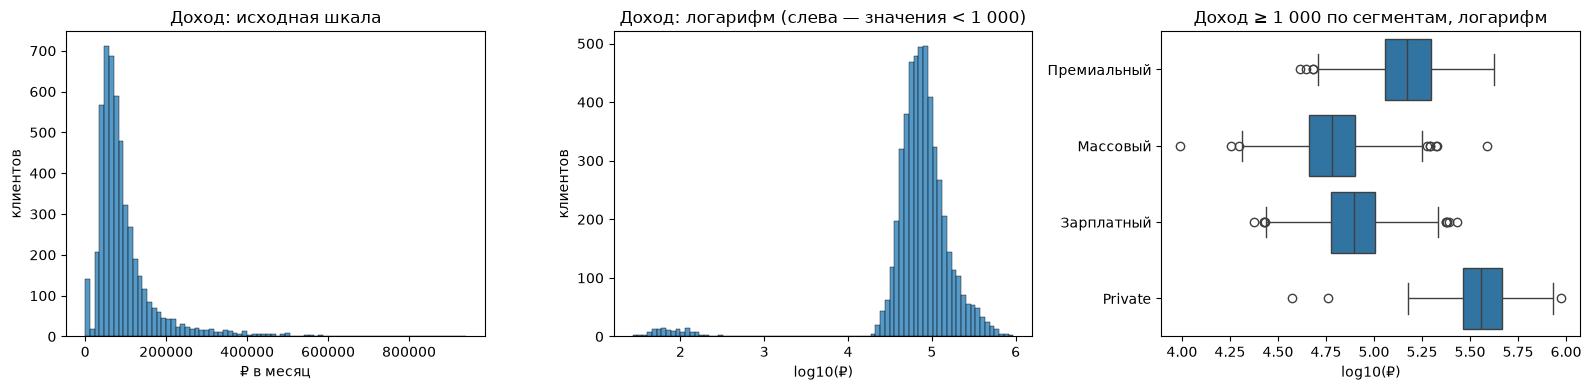

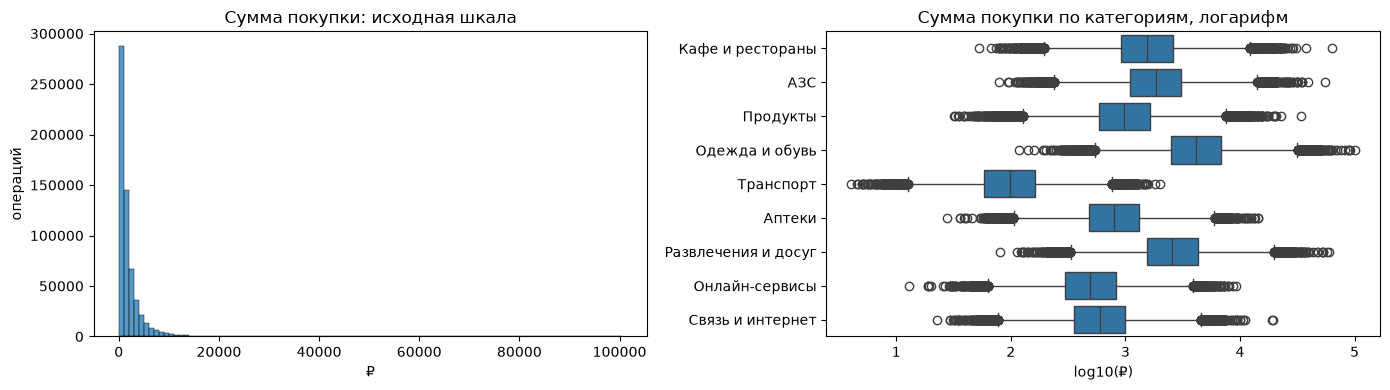

In [24]:
# распределения полей, в которых ищем выбросы (до любых решений)
inc = clients["monthly_income"]
buy = (txn["status"] == "успешно") & (txn["currency"] == "RUB")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(inc.dropna(), bins=80, ax=ax[0])
ax[0].set(title="Доход: исходная шкала", xlabel="₽ в месяц", ylabel="клиентов")
sns.histplot(np.log10(inc.dropna()), bins=80, ax=ax[1])
ax[1].set(title="Доход: логарифм (слева — значения < 1 000)", xlabel="log10(₽)", ylabel="клиентов")
sns.boxplot(x=np.log10(inc.where(inc >= 1000)), y=clients["segment"], ax=ax[2])
ax[2].set(title="Доход ≥ 1 000 по сегментам, логарифм", xlabel="log10(₽)", ylabel="")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(txn.loc[buy, "amount"], bins=100, ax=ax[0])
ax[0].set(title="Сумма покупки: исходная шкала", xlabel="₽", ylabel="операций")
sns.boxplot(x=np.log10(txn.loc[buy, "amount"]), y=txn.loc[buy, "category"], ax=ax[1])
ax[1].set(title="Сумма покупки по категориям, логарифм", xlabel="log10(₽)", ylabel="")
plt.tight_layout(); plt.show()

In [25]:
# --- шаг 1. обнаружение: поля как есть ---
def iqr_out(s):
    """IQR по логарифму — для скошенных вправо величин (доход, суммы)."""
    ls = np.log(s)
    q1, q3 = ls.quantile([0.25, 0.75])
    return (ls < q1 - 1.5 * (q3 - q1)) | (ls > q3 + 1.5 * (q3 - q1))

def iqr_out_plain(s):
    """IQR без логарифма — для симметричных распределений (возраст, стаж)."""
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

units = inc < 1000                                                      # подозрение на сумму в тысячах
inc_ok = inc.where(~units)      # < 1 000 — отдельная аномалия (другая шкала), в IQR не включаем, чтобы не сдвигать границы
inc_out = inc_ok.groupby(clients["segment"]).transform(iqr_out).fillna(False).astype(bool)

age = (REF_DATE - clients["birth_date"]).dt.days / 365.25               # возраст на 30.06.2025
tenure = (REF_DATE - clients["registration_date"]).dt.days / 365.25     # стаж в банке

amt_out = pd.Series(False, index=txn.index)
amt_out[buy] = txn.loc[buy, "amount"].groupby(txn.loc[buy, "category"]).transform(iqr_out)
ret = txn["status"] == "возврат"
ret_out = pd.Series(False, index=txn.index)
ret_out[ret] = iqr_out(txn.loc[ret, "amount"].abs())

detect = pd.DataFrame([
    ("monthly_income", "меньше 1 000 ₽", units.sum(), inc.notna().sum(), "клиентов с известным доходом"),
    ("monthly_income", "IQR по логарифму внутри сегмента", inc_out.sum(), (inc.notna() & ~units).sum(), "клиентов с доходом ≥ 1 000"),
    ("возраст", "IQR", iqr_out_plain(age).sum(), len(clients), f"клиентов (возраст {age.min():.0f}–{age.max():.0f})"),
    ("стаж в банке", "IQR", iqr_out_plain(tenure).sum(), len(clients), f"клиентов (стаж {tenure.min():.1f}–{tenure.max():.1f} лет)"),
    ("amount", "IQR по логарифму внутри категории", amt_out.sum(), buy.sum(), "успешных операций в RUB"),
    ("amount (возвраты)", "IQR по логарифму", ret_out.sum(), ret.sum(), "возвратов"),
], columns=["поле", "правило", "найдено", "проверено", "из чего"]).set_index(["поле", "правило"])
detect.insert(1, "доля, %", (detect["найдено"] / detect["проверено"] * 100).round(2))
show(detect, "Выбросы: обнаружение по полям")
show(clients.loc[inc_out].groupby("segment")["monthly_income"].agg(["size", "min", "max"]),
     "Доход за границами IQR внутри сегмента")
show(txn.loc[amt_out].groupby("category")["amount"].agg(["size", "min", "max"]).round(2),
     "Суммы покупок за границами IQR внутри категории")

**Выбросы: обнаружение по полям**

найдено  доля, %  проверено                       из чего
поле              правило                                                                                     
monthly_income    меньше 1 000 ₽                         139     2.72       5113  клиентов с известным доходом
                  IQR по логарифму внутри сегмента        25     0.50       4974    клиентов с доходом ≥ 1 000
возраст           IQR                                      0     0.00       5667      клиентов (возраст 21–89)
стаж в банке      IQR                                      0     0.00       5667  клиентов (стаж 0.2–15.5 лет)
amount            IQR по логарифму внутри категории     4517     0.75     602605       успешных операций в RUB
amount (возвраты) IQR по логарифму                       181     2.43       7461                     возвратов

**Доход за границами IQR внутри сегмента**

,size,min,max
segment,,,
Private,3,37500.0,940500.0
Зарплатный,9,23700.0,270300.0
Массовый,9,9800.0,387000.0
Премиальный,4,41400.0,48400.0


**Суммы покупок за границами IQR внутри категории**

,size,min,max
category,,,
АЗС,400,79.47,54655.30
Аптеки,353,27.54,14436.79
Кафе и рестораны,610,52.50,63250.43
Одежда и обувь,467,118.48,100524.21
Онлайн-сервисы,325,12.95,9281.27
Продукты,1146,31.74,33748.33
Развлечения и досуг,390,80.45,59223.57
Связь и интернет,362,22.78,19489.93
Транспорт,464,4.07,1989.46


In [26]:
# --- шаг 1. обнаружение: агрегаты по клиенту (успешные, RUB, весь период, клиенты справочника) ---
n_months = 18
client_buy = buy & (txn["txn_datetime"] >= D_START) & (txn["txn_datetime"] < D_END) & txn["client_id"].isin(clients["client_id"])
g = txn[client_buy].groupby("client_id")
per_client = pd.DataFrame({
    "траты в месяц": g["amount"].sum() / n_months,
    "операций в месяц": g.size() / n_months,
    "средний чек": g["amount"].mean(),
})

rows = []
for col in per_client:
    s = per_client[col]
    out = iqr_out(s)
    low = out & (s < s.median())
    rows.append((col, round(s.median(), 1), out.sum(), low.sum(), (out & ~low).sum(), len(per_client),
                 f"{s[low].min():.1f} … {s[low].max():.1f}" if low.any() else "—",
                 f"{s[out & ~low].min():.1f} … {s[out & ~low].max():.1f}" if (out & ~low).any() else "—"))
client_out = pd.DataFrame(rows, columns=["признак", "медиана", "выбросов", "снизу", "сверху", "клиентов",
                                         "диапазон снизу", "диапазон сверху"]).set_index("признак")
show(client_out, "Выбросы на уровне клиента (IQR по логарифму)")

**Выбросы на уровне клиента (IQR по логарифму)**

,медиана,выбросов,снизу,сверху,клиентов,диапазон снизу,диапазон сверху
признак,,,,,,,
траты в месяц,7923.3,307,300,7,5653,3.4 … 742.6,79253.9 … 149904.8
операций в месяц,4.8,386,383,3,5653,0.1 … 0.6,40.2 … 45.8
средний чек,1648.6,186,54,132,5653,61.1 … 750.4,3749.2 … 9357.4


Доход и суммы скошены вправо, поэтому IQR считаем по логарифму. Уровни разные по сегментам (доход) и категориям (суммы), поэтому границы считаем внутри группы. Возраст и стаж распределены симметрично — обычный IQR.

Не проверяем на выбросы: `satisfaction_score` — шкала 1–5, все значения в шкале (2.3); даты — вместо выбросов проверены диапазон и логика (2.3, 2.4); `txn_id`, `mcc_code`, `branch_code` — коды, а не величины; суммы отклонённых операций — операция не состоялась и в расчёт не идёт.

In [27]:
# --- шаг 2. решение по доходу < 1 000:
gap = pd.DataFrame({"максимум среди < 1 000": [inc[units].max()],
                    "минимум среди ≥ 1 000": [inc[~units & inc.notna()].min()]})
show(gap, "Доход: разрыв между значениями меньше и больше 1 000")

buy_2024 = buy & (txn["txn_datetime"] >= D_START) & (txn["txn_datetime"] < B_END)
spend = txn[buy_2024].groupby("client_id")["amount"].sum() / 12          # средние траты в месяц за 2024
by_inc = pd.DataFrame({"доход": inc.values, "траты": clients["client_id"].map(spend).values})
by_inc["группа дохода"] = pd.cut(by_inc["доход"], [0, 1000, 30_000, 50_000, 75_000, 100_000, 150_000, np.inf],
                                 labels=["< 1 000", "1–30 тыс", "30–50 тыс", "50–75 тыс", "75–100 тыс", "100–150 тыс", "> 150 тыс"],
                                 right=False)
check = by_inc.groupby("группа дохода", observed=True).agg(клиентов=("траты", "size"),
                                                           траты_в_месяц_медиана=("траты", "median"))
check["траты / доход, медиана"] = (by_inc["траты"] / by_inc["доход"]).groupby(by_inc["группа дохода"], observed=True).median().round(2)
show(check.round({"траты_в_месяц_медиана": 0}), "Траты в месяц (2024, успешные, RUB) по группам дохода")

**Доход: разрыв между значениями меньше и больше 1 000**

,максимум среди < 1 000,минимум среди ≥ 1 000
0,655.3,9800.0


**Траты в месяц (2024, успешные, RUB) по группам дохода**

,клиентов,траты_в_месяц_медиана,"траты / доход, медиана"
группа дохода,,,
< 1 000,139,9792.0,132.44
1–30 тыс,100,6022.0,0.22
30–50 тыс,840,7326.0,0.17
50–75 тыс,1468,8526.0,0.14
75–100 тыс,1015,9789.0,0.11
100–150 тыс,855,11912.0,0.10
> 150 тыс,696,19063.0,0.08


In [28]:
# доход < 1 000: в рублях быть не может, но какая шкала верна — не доказать → пропуск
before = clients.loc[units, "monthly_income"]
clients.loc[units, "monthly_income"] = np.nan
log("monthly_income", "доход меньше 1 000 ₽ — шкала неизвестна", "monthly_income < 1000", units.sum(),
    f"{before.min():g} … {before.max():g}", "заменено на пропуск", "NaN",
    f"в рублях невозможно: траты в {check.loc['< 1 000', 'траты / доход, медиана']:g} раза больше дохода, "
    f"разрыв {gap.iloc[0, 0]:g} → {gap.iloc[0, 1]:g} (таблицы выше); похоже на тысячи, но это не доказано — сбрасываем")

log("monthly_income", "доход за границами IQR внутри сегмента", "IQR по логарифму внутри сегмента", inc_out.sum(),
    f"{clients.loc[inc_out, 'monthly_income'].min():g} … {clients.loc[inc_out, 'monthly_income'].max():g}", "оставлено", "без изменений",
    "такие доходы правдоподобны для сегмента, ошибку не доказать; исходные значения сохранены")
log("amount", "покупки за границами IQR внутри категории", "IQR по логарифму внутри категории", amt_out.sum(),
    f"{txn.loc[amt_out, 'amount'].min():g} … {txn.loc[amt_out, 'amount'].max():g}", "оставлено", "без изменений",
    "активность считаем числом операций — размер суммы на неё не влияет; признаков ошибки нет")
log("amount (возвраты)", "возврат за границами IQR", "IQR по логарифму", ret_out.sum(),
    f"{txn.loc[ret_out, 'amount'].min():g} … {txn.loc[ret_out, 'amount'].max():g}", "оставлено", "без изменений",
    "возвраты не входят в метрику активности; признаков ошибки нет")
log("траты и операции клиента", "низкая активность за границей IQR", "IQR по логарифму, клиенты справочника",
    client_out.loc["траты в месяц", "снизу"], f"{client_out.loc['траты в месяц', 'диапазон снизу']} ₽ в месяц",
    "оставлено", "без изменений", "низкая активность — это то снижение, которое мы ищем; удалить — потерять целевых клиентов")

# проверка после исправления: траты и доход согласованы
ratio = per_client["траты в месяц"] / clients.set_index("client_id")["monthly_income"].reindex(per_client.index)
show(pd.DataFrame({"клиентов с доходом": [ratio.notna().sum()],
                   "траты / доход, медиана": [round(ratio.median(), 2)],
                   "99-й перцентиль": [round(ratio.quantile(0.99), 2)],
                   "траты больше дохода": [(ratio > 1).sum()]}),
     "Траты и доход после исправления")
show(clients.groupby("segment")["monthly_income"].describe()[["count", "min", "50%", "max"]].round(0),
     "Доход по сегментам после 3.4")

**Траты и доход после исправления**

,клиентов с доходом,"траты / доход, медиана",99-й перцентиль,траты больше дохода
0,4961,0.1,0.52,1


**Доход по сегментам после 3.4**

,count,min,50%,max
segment,,,,
Private,209.0,37500.0,358900.0,940500.0
Зарплатный,1516.0,23700.0,78600.0,270300.0
Массовый,2436.0,9800.0,60700.0,387000.0
Премиальный,813.0,41400.0,147800.0,419900.0


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [29]:
# флаги: строки не удаляем и не исправляем, но помечаем — чтобы учесть в анализе и правилах групп
txn["id_block"] = txn["txn_id"] >= 990000
log("txn_id", "отдельный блок нумерации ID ≥ 990000", "txn_id ≥ 990000", txn["id_block"].sum(),
    f"{txn.loc[txn['id_block'], 'txn_id'].min()} … {txn.loc[txn['id_block'], 'txn_id'].max()}", "оставлено, флаг id_block", "id_block=True",
    "происхождение блока неизвестно, часть дат вне периода (2.3); строки вне периода отсеет фильтр, остальные помечены")

clients["salary_conflict"] = (clients["segment"] == "Зарплатный") & (clients["income_source"] == "Зарплата в другом банке")
log("segment, income_source", "«Зарплатный» сегмент, но зарплата в другом банке", "segment = Зарплатный и income_source = другой банк",
    clients["salary_conflict"].sum(), "Зарплатный + Зарплата в другом банке", "оставлено, флаг salary_conflict", "salary_conflict=True",
    "какое поле верно — неизвестно (источник — со слов клиента); не строим на них правило «зарплатный клиент» без проверки")

age_card = (clients["card_open_date"] - clients["birth_date"]).dt.days / 365.25
clients["age_conflict"] = age_card < 18
log("birth_date, card_open_date", "карта открыта до 18 лет", "возраст при открытии карты < 18", clients["age_conflict"].sum(),
    f"{age_card[clients['age_conflict']].min():.1f} … {age_card[clients['age_conflict']].max():.1f} лет", "оставлено, флаг age_conflict", "age_conflict=True",
    "неверна дата рождения или дата карты — какая, неизвестно (2.4); возраст на 30.06.2025 у всех 21+, на активность не влияет")

show(pd.DataFrame({"строк с флагом": [txn["id_block"].sum(), clients["salary_conflict"].sum(), clients["age_conflict"].sum(), clients["conflict"].sum()],
                   "из": [len(txn), len(clients), len(clients), len(clients)]},
                  index=["txn: id_block", "clients: salary_conflict", "clients: age_conflict", "clients: conflict (3.1)"]),
     "Флаги в очищенных данных")

# фильтры перед расчётом активности: условие и почему отсеиваем
FILTERS = [
    ("операция в периоде 2024-01 … 2025-06", (txn["txn_datetime"] >= D_START) & (txn["txn_datetime"] < D_END),
     "вне периода задачи; все такие строки — из блока ID ≥ 990000"),
    ("статус «успешно»", txn["status"] == "успешно",
     "отклонённая операция не состоялась, возврат — отмена покупки, а не новая активность"),
    ("операция в рублях", txn["currency"] == "RUB",
     "по описанию операции в рублях; курсов EUR/USD нет — суммы несопоставимы, а таких операций 0,4 %"),
    ("клиент есть в справочнике", txn["client_id"].isin(clients["client_id"]),
     "клиента нет в справочнике действующих клиентов на 30.06.2025 (2.4) — в кампанию он не попадёт"),
]
keep = pd.Series(True, index=txn.index)
rows = [("после удаления дублей (3.1)", len(txn), txn["client_id"].nunique())]
for name, cond, why in FILTERS:
    prev = keep.sum()
    keep &= cond
    rows.append((name, keep.sum(), txn.loc[keep, "client_id"].nunique()))
    log("txn (фильтр)", f"не проходит: {name}", name, prev - keep.sum(), f"{prev} операций",
        "исключено из расчёта активности", f"{keep.sum()} операций", why)

funnel = pd.DataFrame(rows, columns=["шаг", "операций", "клиентов"]).set_index("шаг")
funnel["отсеяно операций"] = (-funnel["операций"].diff()).fillna(0).astype(int)
funnel["осталось, %"] = (funnel["операций"] / len(txn) * 100).round(1)
show(funnel, f"Воронка фильтров (вход — {len(txn)} операций после удаления дублей)")

txn_act = txn[keep].copy()                                               # операции для расчёта активности
show(pd.DataFrame({"операций": [len(txn_act)], "клиентов": [txn_act["client_id"].nunique()],
                   "из них блок ID ≥ 990000": [txn_act["id_block"].sum()],
                   "без времени": [(~txn_act["has_time"]).sum()]}, index=["txn_act"]),
     "Что идёт в расчёт активности")
facts["txn_act_rows"] = len(txn_act)
facts["txn_act_clients"] = int(txn_act["client_id"].nunique())

**Флаги в очищенных данных**

,строк с флагом,из
txn: id_block,220,624801
clients: salary_conflict,102,5667
clients: age_conflict,7,5667
clients: conflict (3.1),15,5667


**Воронка фильтров (вход — 624801 операций после удаления дублей)**

,операций,клиентов,отсеяно операций,"осталось, %"
шаг,,,,
после удаления дублей (3.1),624801,5987,0,100.0
операция в периоде 2024-01 … 2025-06,624726,5987,75,100.0
статус «успешно»,604949,5986,19777,96.8
операция в рублях,602531,5986,2418,96.4
клиент есть в справочнике,576422,5653,26109,92.3


**Что идёт в расчёт активности**

,операций,клиентов,из них блок ID ≥ 990000,без времени
txn_act,576422,5653,133,45701


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [30]:
# журнал собран по ходу 3.1–3.5 (функция log); здесь — в таблицу с колонками из задания
cleaning_log = pd.DataFrame(cleaning_log, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])
cleaning_log.index = range(1, len(cleaning_log) + 1)
show(cleaning_log, f"Журнал изменений: {len(cleaning_log)} решений")
show(cleaning_log["action"].value_counts().rename("решений").to_frame(), "Журнал: что сделано")
cleaning_log.to_csv("cleaning_log.csv", index=False)

**Журнал изменений: 24 решений**

,field,issue,scope,n_rows,value_before,action,value_after,rationale
1,все поля,полная копия строки клиента,дубли по всем полям,40,5722 строк,удалено,5682 строк,копия не несёт информации и удваивает клиента ...
2,"city, segment",у client_id две версии строки,"client_id: C004190, C000559, C000751, C001089,...",15,2 строки на клиента,"оставлена первая, флаг conflict",1 строка на клиента,истинная версия неизвестна; флаг позволяет иск...
3,все поля,полная копия операции,дубли по всем полям,1292,626301 строк,удалено,625009 строк,одна операция посчитана дважды — завышает акти...
4,txn_datetime,копия операции с датой без времени,txn_id с двумя версиями,208,2024-01-01 13:11:26 и 2024-01-01,удалена версия без времени,2024-01-01 13:11:26,"та же операция: совпадает всё, кроме времени (..."
5,"birth_date, registration_date, card_open_date",даты в разных форматах (ГГГГ-ММ-ДД и ДД.ММ.ГГГГ),все строки,5667,1980-05-01 / 23.04.2011 / 08.12.2016,приведено к datetime,1980-05-01 / 2011-04-23 / 2016-12-08,формат задан явно для каждого поля — день и ме...
6,txn_datetime,у части операций только дата,все строки,624801,2024-01-01,"приведено к datetime, добавлен флаг has_time","2024-01-01 00:00:00, has_time=False",время потеряно у 49586 операций; по дням и мес...
7,city,один город записан по-разному,все строки с нестандартным написанием,1658,"17 написаний: « москва», «СПб», «казань», «г.Е...",нормализация,"6 городов: Москва, Санкт-Петербург, Новосибирс...","регистр, «г.», пробелы и сокращения (СПб, Н. Н..."
8,category,одна категория записана по-разному,все строки с нестандартным написанием,53842,"«Кафе/рестораны», «кафе и рестораны», «Связь и...",нормализация,9 категорий,по описанию категорий девять; различие только ...
9,mcc_code,код торговой точки не совпадает с категорией,mcc_code ≠ основного кода категории,1653,category ≠ категории по mcc_code,оставлено,без изменений,какое из двух полей верно — неизвестно; в анал...
10,monthly_income,служебное значение -999,monthly_income == -999,51,-999,заменено на пропуск,NaN,отрицательного дохода не бывает; -999 — заглуш...


**Журнал: что сделано**

,решений
action,
оставлено,7
исключено из расчёта активности,4
удалено,2
нормализация,2
заменено на пропуск,2
"оставлена первая, флаг conflict",1
удалена версия без времени,1
приведено к datetime,1
"приведено к datetime, добавлен флаг has_time",1


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

**Количественные признаки: 5667 клиентов справочника**

,count,пропусков,mean,std,min,5%,25%,50%,75%,95%,max
"возраст, лет",5667.0,0.0,53.6,14.0,21.1,33.6,43.2,52.0,62.4,80.6,88.9
"стаж в банке, лет",5667.0,0.0,7.8,3.3,0.2,2.2,5.4,7.9,10.1,13.0,15.5
"доход, ₽",4974.0,693.0,100572.3,83644.5,9800.0,35865.0,54800.0,76500.0,112300.0,257775.0,940500.0
оценка 1–5,2286.0,3381.0,3.3,1.4,1.0,1.0,2.0,3.0,5.0,5.0,5.0
"операций в месяц, 2024",5667.0,0.0,6.0,4.6,0.0,0.0,3.0,5.2,8.1,14.3,41.8
"операций в месяц, I пол. 2025",5667.0,0.0,5.0,4.4,0.0,0.7,1.8,3.7,6.7,13.6,53.7
активных месяцев из 18,5667.0,0.0,15.5,4.5,0.0,4.0,16.0,18.0,18.0,18.0,18.0
"средний чек, ₽ (RUB)",5653.0,14.0,1820.1,706.1,61.1,1059.3,1381.8,1648.6,2058.7,3206.2,9357.4


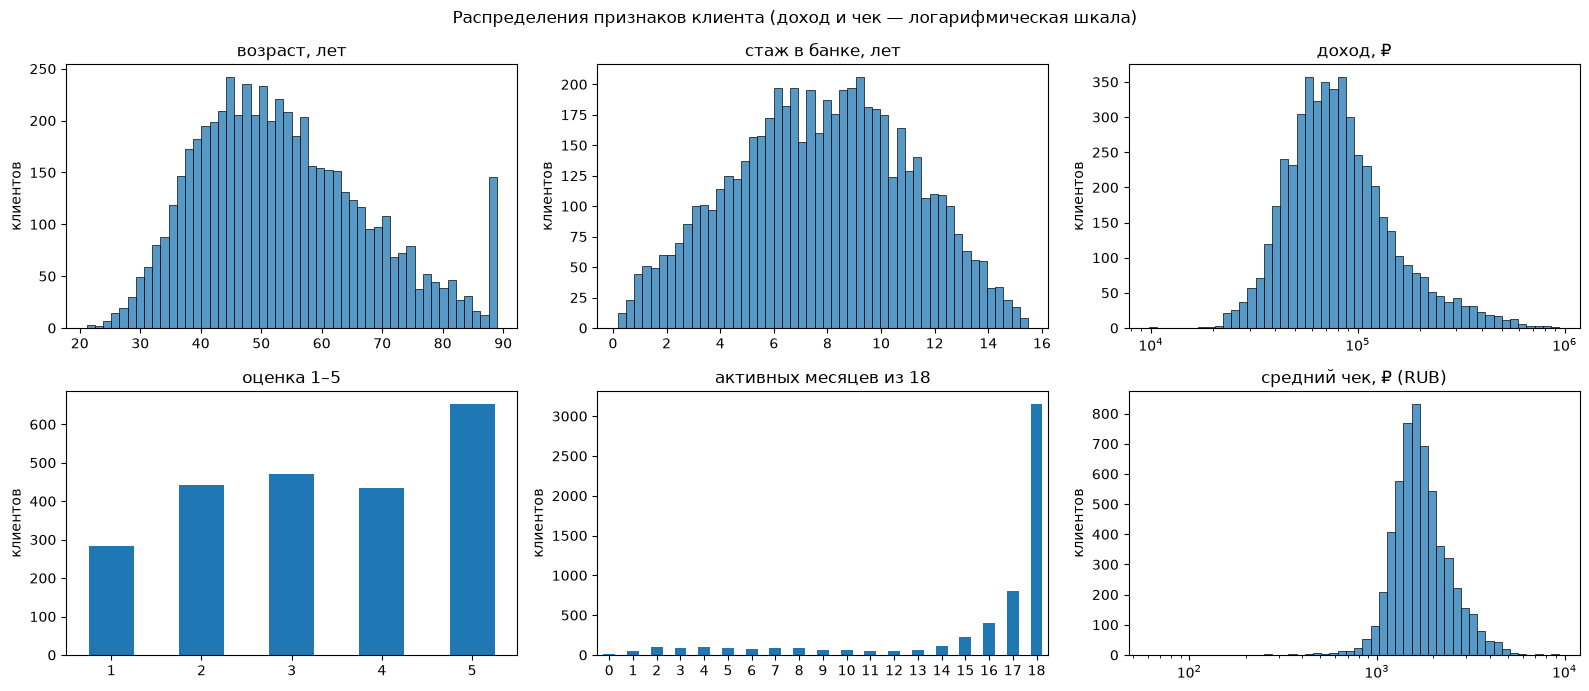

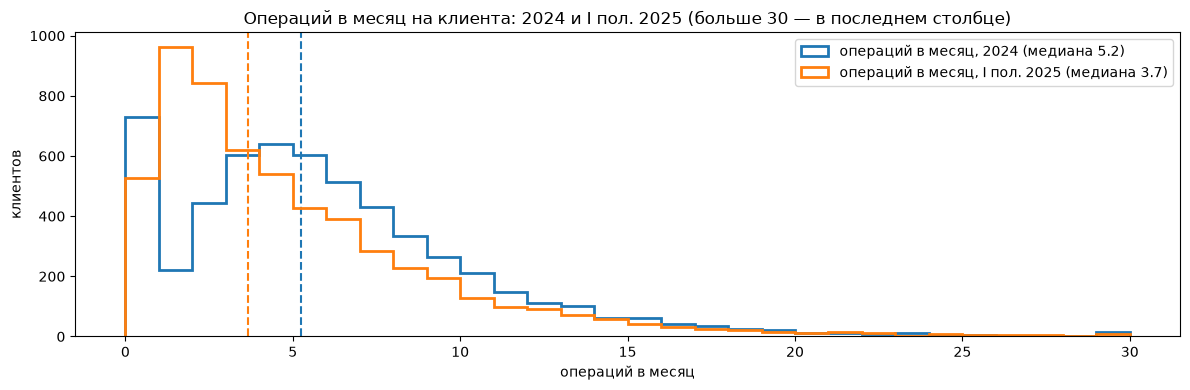

**Год рождения: самые ранние годы**

birth_date,1936,1937,1938,1939,1940,1941,1942,1943,1944,1945,1946,1947
клиентов,67,79,8,16,8,28,21,23,36,30,33,33


**Пик в нуле на «операций в месяц, 2024»: когда открыта текущая карта**

,клиентов без операций в 2024,из них карта открыта в 2025,карта открыта в 2024,пришли в банк в 2025,"всего клиентов с картой, открытой в периоде"
клиентов,406,349,57,12,827


In [31]:
# количественные признаки клиента (на 30.06.2025) и активность по операциям txn_act
clients["age"] = (REF_DATE - clients["birth_date"]).dt.days / 365.25
clients["tenure"] = (REF_DATE - clients["registration_date"]).dt.days / 365.25
txn_act["month"] = txn_act["txn_datetime"].dt.to_period("M")
txn_act["period"] = np.where(txn_act["txn_datetime"] < B_END, "base", "eval")      # база 2024, оценка I пол. 2025

g = txn_act.groupby("client_id")
per = pd.DataFrame({
    "операций в месяц, 2024": g["period"].agg(lambda s: (s == "base").sum()) / 12,
    "операций в месяц, I пол. 2025": g["period"].agg(lambda s: (s == "eval").sum()) / 6,
    "активных месяцев из 18": g["month"].nunique(),
    "средний чек, ₽ (RUB)": txn_act[txn_act["currency"] == "RUB"].groupby("client_id")["amount"].mean(),
})
# у клиентов без операций — ноль операций, а не пропуск; средний чек без покупок не определён и остаётся NaN
count_cols = ["операций в месяц, 2024", "операций в месяц, I пол. 2025", "активных месяцев из 18"]
per = per.reindex(clients["client_id"])
per[count_cols] = per[count_cols].fillna(0)

quant = clients.set_index("client_id")[["age", "tenure", "monthly_income", "satisfaction_score"]].rename(columns={
    "age": "возраст, лет", "tenure": "стаж в банке, лет", "monthly_income": "доход, ₽", "satisfaction_score": "оценка 1–5"})
quant = quant.join(per)

# описательные статистики: меру центра и разброса выбираем по типу шкалы и форме распределения
ORDINAL = {"оценка 1–5"}                                   # порядковая шкала: расстояния между баллами не равны — среднего нет
rows = []
for col in quant:
    s = quant[col].dropna()
    q1, med_, q3 = s.quantile([0.25, 0.5, 0.75])
    skew = s.skew()
    if col in ORDINAL:
        center, spread = f"медиана {med_:g}, мода {s.mode()[0]:g}", f"Q1–Q3: {q1:g}–{q3:g}"
        why = "порядковая шкала — среднее и ст. отклонение не определены"
    elif abs(skew) < 0.5:
        center, spread = f"среднее {s.mean():.1f} (медиана {med_:.1f})", f"ст. откл. {s.std():.1f}"
        why = f"почти симметрично (асимметрия {skew:.2f}) — среднее и медиана совпадают"
    else:
        center, spread = f"медиана {med_:,.1f}".replace(",", " "), f"IQR {q1:,.1f}–{q3:,.1f}".replace(",", " ")
        side = "вправо" if skew > 0 else "влево"
        why = f"скошено {side} (асимметрия {skew:.2f}) — среднее {s.mean():,.1f} тянет хвост, медиана устойчива".replace(",", "\u00a0")
    rows.append((col, len(s), len(quant) - len(s), round(skew, 2), center, spread, why))
stats = pd.DataFrame(rows, columns=["признак", "n", "пропусков", "асимметрия", "центр", "разброс", "почему эта мера"]).set_index("признак")
show(stats, f"Описательные статистики: {len(quant)} клиентов справочника (возраст и стаж — на 30.06.2025; операции — за 2024 и I пол. 2025)")

# признаки клиента — по одному графику на признак
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, ["возраст, лет", "стаж в банке, лет", "доход, ₽", "оценка 1–5", "активных месяцев из 18", "средний чек, ₽ (RUB)"]):
    s = quant[col].dropna()
    if col in ("оценка 1–5", "активных месяцев из 18"):
        s.astype(int).value_counts().sort_index().plot.bar(ax=ax, rot=0)
    else:
        sns.histplot(s, bins=50, log_scale=col in ("доход, ₽", "средний чек, ₽ (RUB)"), ax=ax)
    ax.set(title=col, xlabel={"оценка 1–5": "балл", "активных месяцев из 18": "месяцев с операциями"}.get(col, col), ylabel="клиентов")
plt.suptitle("Распределения признаков клиента (доход и чек — логарифмическая шкала)")
plt.tight_layout(); plt.show()

# операций в месяц: 2024 и I пол. 2025 на одной оси — так сдвиг виден сразу
fig, ax = plt.subplots(figsize=(12, 4))
bins = np.arange(0, 31, 1)
for col, color in [("операций в месяц, 2024", "tab:blue"), ("операций в месяц, I пол. 2025", "tab:orange")]:
    s = quant[col].dropna()
    ax.hist(s.clip(upper=30), bins=bins, histtype="step", lw=2, color=color, label=f"{col} (медиана {s.median():.1f})")
    ax.axvline(s.median(), color=color, ls="--")
ax.set(title="Операций в месяц на клиента: 2024 и I пол. 2025 (больше 30 — в последнем столбце)",
       xlabel="операций в месяц", ylabel="клиентов")
ax.legend(); plt.tight_layout(); plt.show()

# два пика, которые видны на графиках: возраст ~89 лет и ноль операций в 2024
years = clients["birth_date"].dt.year.value_counts().sort_index()
show(years.loc[:1947].rename("клиентов").to_frame().T, "Год рождения: самые ранние годы")

zero_base = per.index[per["операций в месяц, 2024"] == 0]
zb = clients.set_index("client_id").loc[zero_base]
show(pd.DataFrame({
    "клиентов без операций в 2024": [len(zb)],
    "из них карта открыта в 2025": [(zb["card_open_date"] >= B_END).sum()],
    "карта открыта в 2024": [((zb["card_open_date"] >= D_START) & (zb["card_open_date"] < B_END)).sum()],
    "пришли в банк в 2025": [(zb["registration_date"] >= B_END).sum()],
    "всего клиентов с картой, открытой в периоде": [(clients["card_open_date"] >= D_START).sum()],
}, index=["клиентов"]), "Пик в нуле на «операций в месяц, 2024»: когда открыта текущая карта")

**Что видно в 5.1**
- **Возраст** 21–89 лет, медиана 52. На 1936–1937 годы рождения приходится 146 клиентов, а в соседних годах — от 8 до 36: скопление у самой ранней даты. Причина по данным неизвестна; на активность это не влияет, но разрез «60+» трактуем осторожно.
- **Доход** после очистки: медиана 76,5 тыс. ₽, распределение скошено вправо (на логарифме — почти симметричное), 693 пропуска.
- **Оценка** есть у 2 286 клиентов из 5 667; самая частая — «5».
- **Операций в месяц на клиента:** медиана 5,2 в 2024 и 3,7 в I полугодии 2025 — на общем графике видно, что распределение целиком сдвинулось влево. Здесь расчёт простой: за 2024 делим на 12 месяцев у всех; поправка на дату открытия карты — в разделе 6.
- **Пик в нуле в 2024:** 392 клиента без единой операции за год, у 336 из них текущая карта открыта в 2025. Операций раньше открытия текущей карты в данных практически нет (одна, 2.4). Всего 827 клиентов открыли текущую карту внутри периода — их база неполная, это нужно учесть в метрике (раздел 6).

### 5.2. Частотные характеристики категориальных признаков

**Клиенты: частоты (5667 клиентов)**

клиентов  доля, %
поле             значение                                  
segment          Массовый                     2894     51.1
                 Зарплатный                   1637     28.9
                 Премиальный                   904     16.0
                 Private                       232      4.1
loyalty_tier     Базовый                      2884     50.9
                 Серебро                      1507     26.6
                 Золото                        980     17.3
                 Платина                       296      5.2
card_type        Дебетовая                    3940     69.5
                 Кредитная                    1222     21.6
                 Премиальная                   505      8.9
city             Москва                       1614     28.5
                 Санкт-Петербург               984     17.4
                 Новосибирск                   943     16.6
                 Екатеринбург                  722     12.7
                 Нижний Новгород               712     12.6
                 Казань                        692     12.2
gender           Ж                            2835     50.0
                 М                            2832     50.0
income_source    Зарплата в нашем банке       2606     46.0
                 Зарплата в другом банке      1544     27.2
                 Не указан                    1517     26.8
has_mobile_app   True                         3440     60.7
                 False                        2227     39.3
marketing_opt_in True                         4955     87.4
                 False                         712     12.6

**Операции в расчёте активности: частоты (576422 операций)**

операций  доля, %
поле     значение                              
category Продукты               152622     26.5
         Кафе и рестораны        78518     13.6
         Транспорт               60749     10.5
         Одежда и обувь          58852     10.2
         АЗС                     53171      9.2
         Связь и интернет        45730      7.9
         Развлечения и досуг     43832      7.6
         Аптеки                  42400      7.4
         Онлайн-сервисы          40548      7.0
channel  Карта                  294903     51.2
         СБП                    101375     17.6
         Токен                   97457     16.9
         Онлайн-банк             82687     14.3

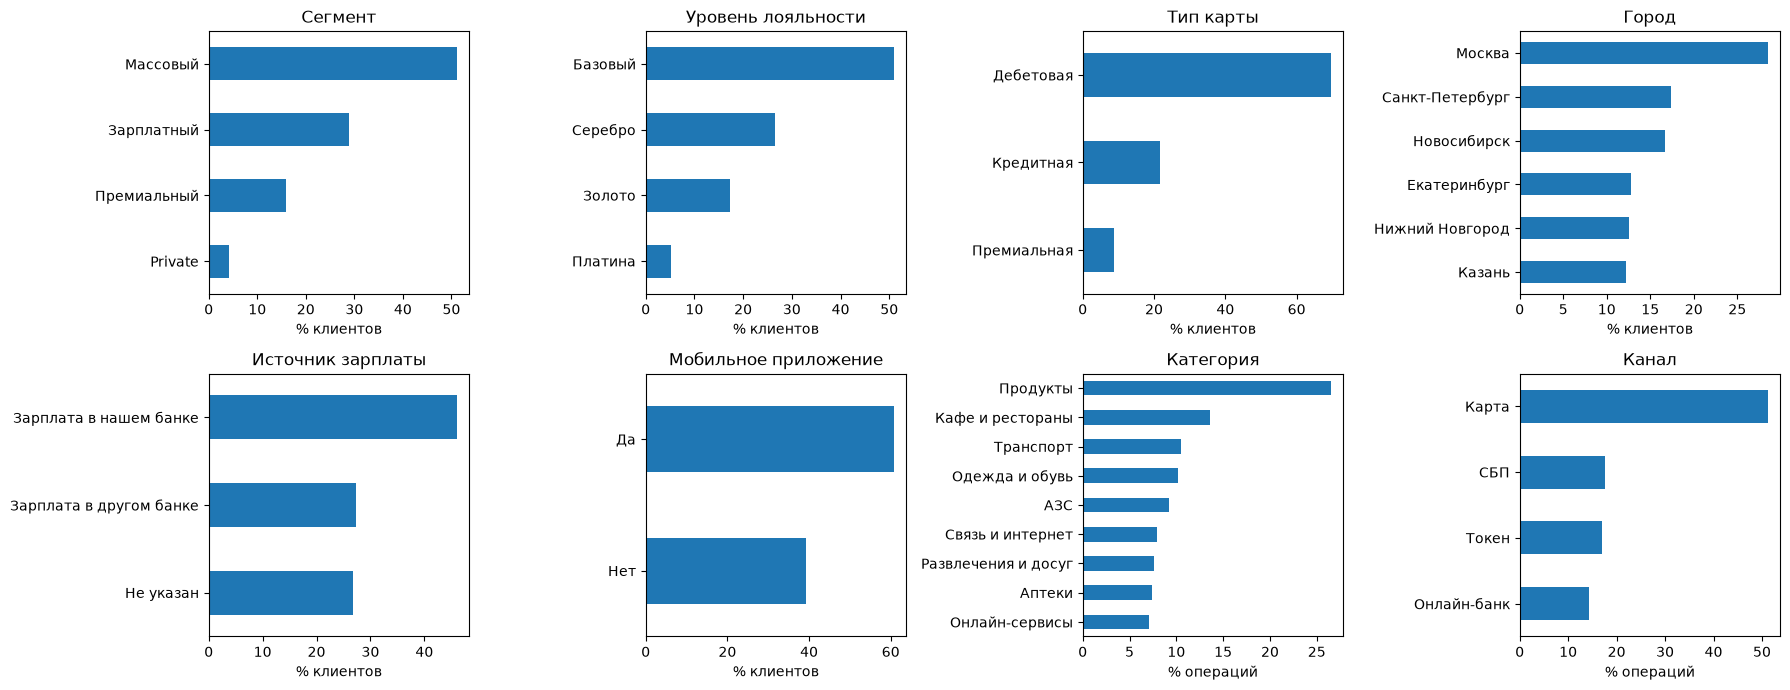

**Сегмент × источник зарплаты, клиентов**

income_source,Зарплата в другом банке,Зарплата в нашем банке,Не указан,всего
segment,,,,
Private,86,76,70,232
Зарплатный,102,1458,77,1637
Массовый,1033,708,1153,2894
Премиальный,323,364,217,904
всего,1544,2606,1517,5667


**Сегмент × тип карты, клиентов**

card_type,Дебетовая,Кредитная,Премиальная,всего
segment,,,,
Private,48,31,153,232
Зарплатный,1192,414,31,1637
Массовый,2309,557,28,2894
Премиальный,391,220,293,904
всего,3940,1222,505,5667


In [32]:
# частоты категориальных признаков: клиенты (справочник) и операции (txn_act)
def freq(df, cols, unit):
    out = []
    for col in cols:
        vc = df[col].value_counts(dropna=False)
        out.append(pd.DataFrame({"поле": col, "значение": vc.index.astype(str), unit: vc.values,
                                 "доля, %": (vc.values / len(df) * 100).round(1)}))
    return pd.concat(out).set_index(["поле", "значение"])

client_cats = ["segment", "loyalty_tier", "card_type", "city", "gender", "income_source", "has_mobile_app", "marketing_opt_in"]
txn_cats = ["category", "channel"]                       # валюта после 3.5 только RUB
show(freq(clients, client_cats, "клиентов"), f"Клиенты: частоты ({len(clients)} клиентов)")
show(freq(txn_act, txn_cats, "операций"), f"Операции в расчёте активности: частоты ({len(txn_act)} операций)")

TITLES = {"segment": "Сегмент", "loyalty_tier": "Уровень лояльности", "card_type": "Тип карты", "city": "Город",
          "income_source": "Источник зарплаты", "has_mobile_app": "Мобильное приложение", "category": "Категория", "channel": "Канал"}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, TITLES):
    df = txn_act if col in txn_cats else clients
    values = df[col].replace({True: "Да", False: "Нет"}) if col == "has_mobile_app" else df[col]
    (values.value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax)
    ax.set(title=TITLES[col], xlabel=f"% {'операций' if df is txn_act else 'клиентов'}", ylabel="")
plt.tight_layout(); plt.show()

# сочетания, которые понадобятся для групп: сегмент × источник зарплаты, сегмент × тип карты
show(pd.crosstab(clients["segment"], clients["income_source"], margins=True, margins_name="всего"), "Сегмент × источник зарплаты, клиентов")
show(pd.crosstab(clients["segment"], clients["card_type"], margins=True, margins_name="всего"), "Сегмент × тип карты, клиентов")

**Что видно в 5.2**
- Половина клиентов — «Массовый» сегмент и «Базовый» уровень лояльности; Private — 4 %.
- Москва — 28 % клиентов, остальные пять городов — по 12–17 %.
- Источник зарплаты: «в нашем банке» — 46 %, «Не указан» — 27 %.
- Среди операций больше всего «Продукты» (27 %), по каналам — «Карта» (51 %). Операции в EUR/USD исключены фильтром в 3.5.
- Сегмент и источник зарплаты связаны: у «Зарплатных» 89 % получают зарплату у нас, у «Массовых» — 24 %. Значит, разрезы по ним пересекаются, и в разделе 7 надо проверять, какой из признаков первичен.

### 5.3. Динамика по месяцам

**Помесячно: операции, активные клиенты, сумма**

,операций,активных_клиентов,сумма_руб,операций на активного клиента,"доля операций без времени, %"
month,,,,,
2024-01,24019,4634,46713609.0,5.2,7.7
2024-02,29942,4720,56674502.3,6.3,8.0
2024-03,34920,4757,66850372.8,7.3,7.9
2024-04,33925,4755,64569782.8,7.1,7.9
2024-05,31082,4745,58970992.4,6.6,8.0
2024-06,33471,4754,62669041.0,7.0,7.9
2024-07,34765,4785,66514064.1,7.3,7.8
2024-08,36092,4892,68351156.2,7.4,7.8
2024-09,34412,4929,65533998.2,7.0,8.0


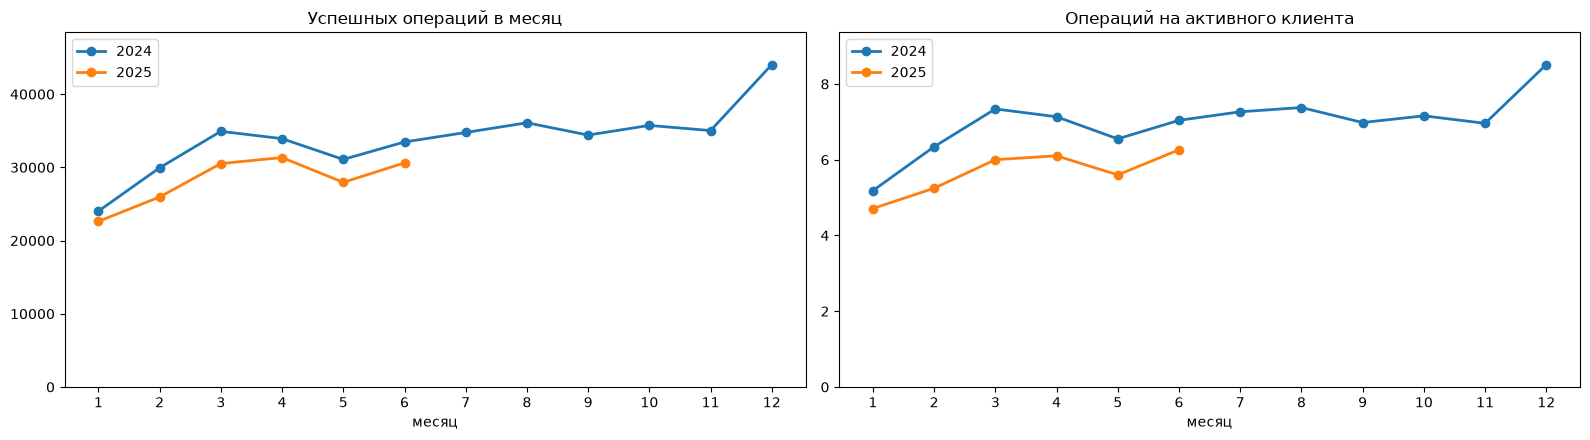

**Падение зависит от базы сравнения**

,"было, операций в месяц","стало, операций в месяц","изменение, %"
весь 2024 → I пол. 2025,33952.3,28165.7,-17.0
I пол. 2024 → I пол. 2025,31226.5,28165.7,-9.8


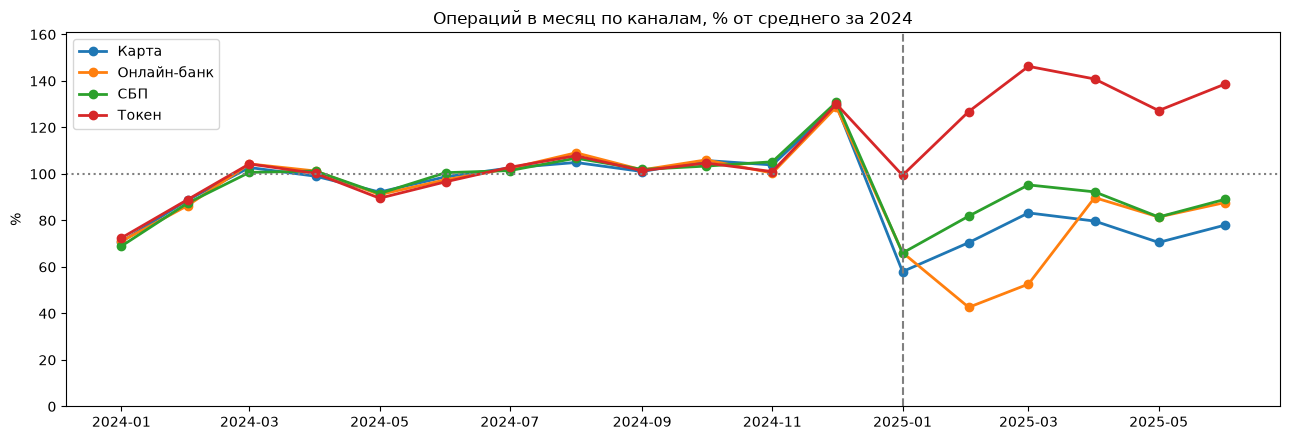

**Каналы, % от среднего за 2024: конец 2024 и 2025**

month,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
channel,,,,,,,,
Карта,104.0,130.0,58.0,70.0,83.0,80.0,71.0,78.0
Онлайн-банк,100.0,129.0,66.0,43.0,53.0,90.0,81.0,88.0
СБП,105.0,131.0,66.0,82.0,95.0,92.0,81.0,89.0
Токен,101.0,130.0,99.0,127.0,146.0,141.0,127.0,139.0


In [33]:
# помесячная динамика по операциям txn_act
monthly = txn_act.groupby("month").agg(операций=("txn_id", "size"), активных_клиентов=("client_id", "nunique"),
                                       сумма_руб=("amount", "sum"))           # после 3.5 все операции в рублях
monthly["операций на активного клиента"] = monthly["операций"] / monthly["активных_клиентов"]
monthly["доля операций без времени, %"] = (~txn_act["has_time"]).groupby(txn_act["month"]).mean() * 100
show(monthly.round(1), "Помесячно: операции, активные клиенты, сумма")

# одинаковые месяцы рядом: 2024 и 2025 на одной оси — видно и сезонность, и разрыв между годами
by_year = monthly.assign(год=monthly.index.year, месяц=monthly.index.month)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, col, title in [(axes[0], "операций", "Успешных операций в месяц"),
                       (axes[1], "операций на активного клиента", "Операций на активного клиента")]:
    ax.set_ylabel("операций в месяц" if col == "операций" else "операций в месяц на клиента")
    for year, color in [(2024, "tab:blue"), (2025, "tab:orange")]:
        d = by_year[by_year["год"] == year]
        ax.plot(d["месяц"], d[col], marker="o", color=color, lw=2, label=str(year))
    ax.set(title=title, xticks=range(1, 13), xlabel="месяц", ylim=(0, by_year[col].max() * 1.1))
    ax.legend()
plt.tight_layout(); plt.show()

# падение зависит от того, с чем сравнивать: со всем 2024 (с декабрьским пиком) или с теми же месяцами 2024
h1 = monthly.index.month <= 6
cmp = pd.DataFrame({
    "весь 2024 → I пол. 2025": [monthly.loc[monthly.index.year == 2024, "операций"].mean(), monthly.loc[monthly.index.year == 2025, "операций"].mean()],
    "I пол. 2024 → I пол. 2025": [monthly.loc[h1 & (monthly.index.year == 2024), "операций"].mean(), monthly.loc[h1 & (monthly.index.year == 2025), "операций"].mean()],
}, index=["было, операций в месяц", "стало, операций в месяц"]).T
cmp["изменение, %"] = (cmp.iloc[:, 1] / cmp.iloc[:, 0] - 1) * 100
show(cmp.round(1), "Падение зависит от базы сравнения")

# каналы в процентах от своего среднего за 2024 — крупная «Карта» не заслоняет остальные
by_channel = txn_act.groupby(["month", "channel"]).size().unstack()
ch_idx = by_channel / by_channel[by_channel.index.year == 2024].mean() * 100
fig, ax = plt.subplots(figsize=(13, 4.5))
for ch in ch_idx:
    ax.plot(ch_idx.index.to_timestamp(), ch_idx[ch], marker="o", lw=2, label=ch)
ax.axhline(100, color="grey", ls=":"); ax.axvline(B_END, color="grey", ls="--")
ax.set(title="Операций в месяц по каналам, % от среднего за 2024", xlabel="месяц", ylabel="% от среднего за 2024", ylim=(0, ch_idx.max().max() * 1.1))
ax.legend(); plt.tight_layout(); plt.show()
show(ch_idx.loc["2024-11":].round(0).T, "Каналы, % от среднего за 2024: конец 2024 и 2025")

**Что видно в 5.3**
- **Сезонность:** декабрь 2024 — пик (44 тыс. операций), январь — провал; январь 2024 тоже ниже остальных месяцев.
- **Падение зависит от базы:** −17,0 % к среднему за весь 2024 и −9,8 % к I полугодию 2024. Выбор базы — решение для раздела 6.
- **Активных клиентов в месяц** почти столько же (4,6–5,2 тыс.), а операций на активного клиента меньше: снижение — за счёт частоты операций, а не потому что клиенты массово перестали платить.
- **Доля операций без времени** ~8 % во всех месяцах — этот дефект не связан с периодом и на сравнение не влияет.
- **Каналы** (в % от своего среднего за 2024): «Токен» с февраля 2025 выше уровня 2024 (127–146 %), «Карта» — 58–83 %. «Онлайн-банк» в феврале–марте 2025 провалился до 43–53 % и в апреле вернулся к 90 % — у других каналов такого провала нет; причина по данным не видна.

### 5.4. Разрезы и связи между признаками

**Операций на клиента в месяц по разрезам (в среднем по всем: -17.0 %)**

клиентов  операций в месяц, 2024  операций в месяц, I пол. 2025  изменение, %
разрез           значение                                                                                              
segment          Private                       232                     7.6                            6.8         -10.5
                 Зарплатный                   1637                     6.5                            6.1          -5.9
                 Массовый                     2894                     5.3                            3.7         -30.0
                 Премиальный                   904                     6.9                            6.4          -6.1
loyalty_tier     Базовый                      2884                     5.6                            4.3         -22.9
                 Золото                        980                     6.6                            6.2          -5.9
                 Платина                       296                     6.7                            6.4          -4.6
                 Серебро                      1507                     6.1                            5.1         -17.3
card_type        Дебетовая                    3940                     5.8                            4.7         -18.5
                 Кредитная                    1222                     6.1                            5.1         -16.2
                 Премиальная                   505                     7.1                            6.5          -9.2
city             Екатеринбург                  722                     6.2                            5.2         -15.9
                 Казань                        692                     6.1                            5.1         -16.0
                 Москва                       1614                     6.2                            5.2         -15.8
                 Нижний Новгород               712                     6.0                            5.1         -14.2
                 Новосибирск                   943                     5.1                            3.8         -26.3
                 Санкт-Петербург               984                     6.2                            5.3         -15.3
income_source    Зарплата в другом банке      1544                     5.8                            4.6         -20.9
                 Зарплата в нашем банке       2606                     6.2                            5.5         -11.5
                 Не указан                    1517                     5.8                            4.5         -23.2
has_mobile_app   False                        2227                     5.7                            4.4         -23.7
                 True                         3440                     6.2                            5.4         -13.0
marketing_opt_in False                         712                     5.9                            4.8         -18.2
                 True                         4955                     6.0                            5.0         -16.9
gender           Ж                            2835                     5.9                            5.0         -16.2
                 М                            2832                     6.0                            5.0         -17.9

**Операций на клиента в месяц: возраст и доход (доход — квартили, без пропусков)**

клиентов  операций в месяц, 2024  операций в месяц, I пол. 2025  изменение, %
разрез            значение                                                                                   
возрастная группа до 30               98                     7.9                            7.4          -6.2
                  30–44             1633                     6.8                            5.8         -14.6
                  45–59             2255                     6.1                            5.1         -16.2
                  60+               1681                     4.9                            3.8         -22.8
доход             Q1 (низкий)       1247                     5.7                            4.3         -23.4
                  Q2                1241                     5.9                            4.6         -21.1
                  Q3                1243                     5.8                            4.9         -14.6
                  Q4 (высокий)      1243                     6.5                            5.9          -8.9

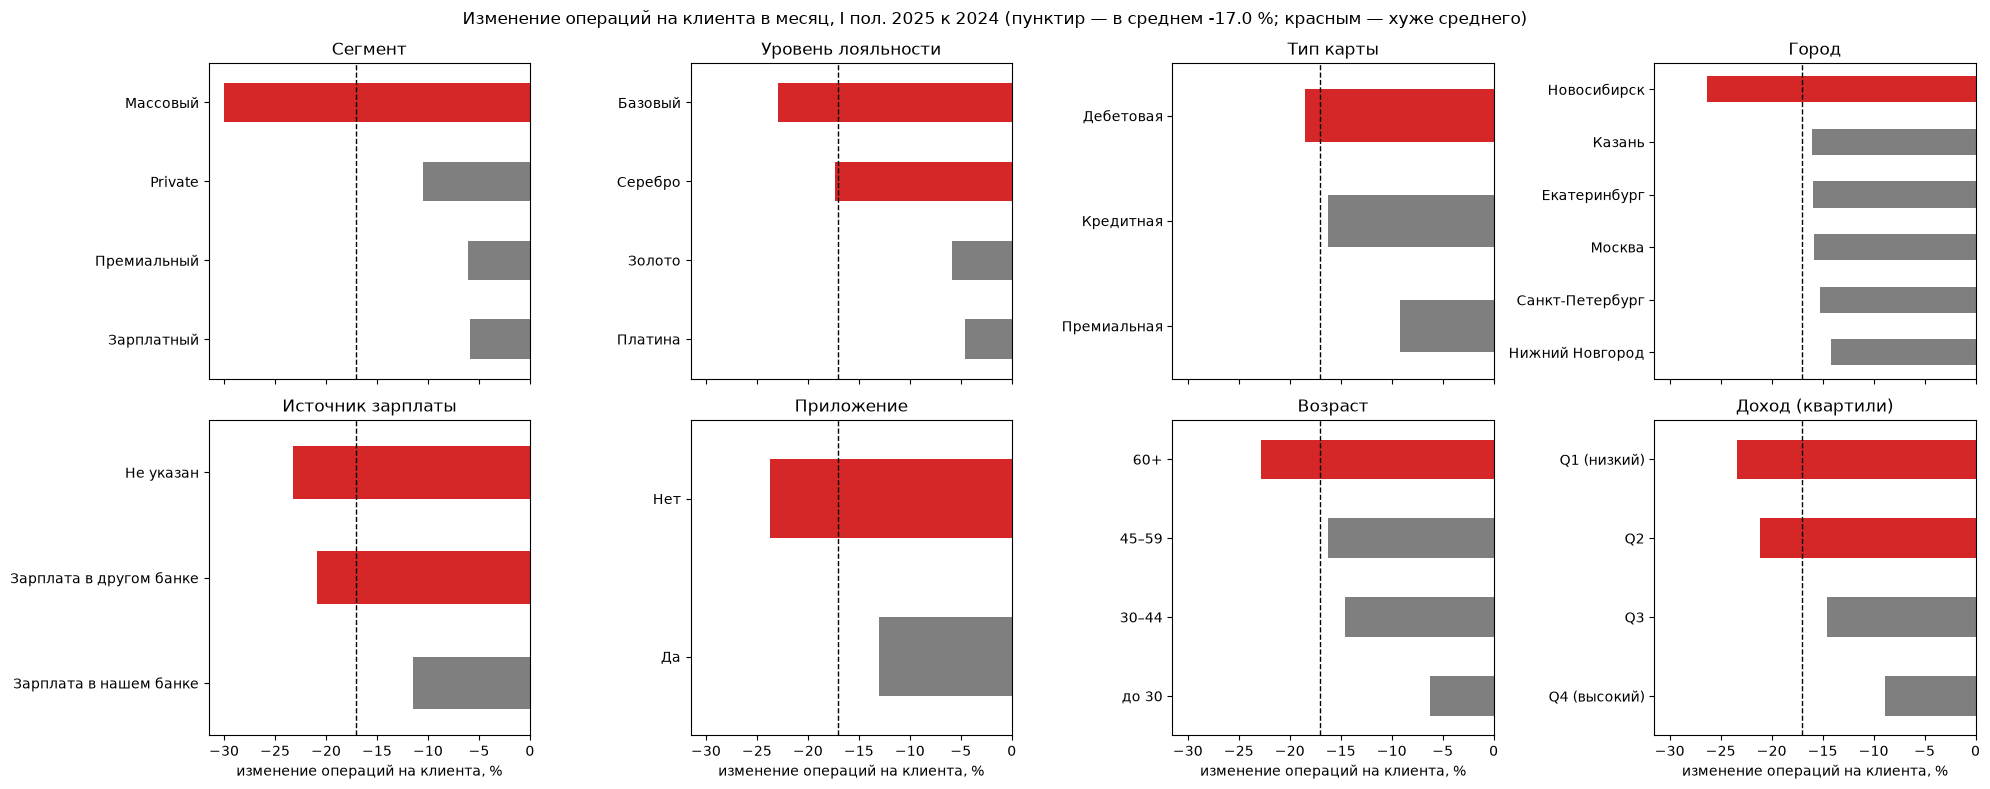

**Операций в месяц по категориям**

period,"в месяц, 2024","в месяц, I пол. 2025","изменение, %"
category,,,
Кафе и рестораны,4805.9,3474.5,-27.7
Аптеки,2498.6,2069.5,-17.2
Транспорт,3575.7,2973.5,-16.8
Связь и интернет,2689.1,2243.5,-16.6
Продукты,8952.1,7532.8,-15.9
Онлайн-сервисы,2365.4,2027.2,-14.3
Одежда и обувь,3425.8,2957.0,-13.7
АЗС,3094.7,2672.5,-13.6
Развлечения и досуг,2545.1,2215.2,-13.0


**Операций в месяц по каналам**

period,"в месяц, 2024","в месяц, I пол. 2025","изменение, %"
channel,,,
Онлайн-банк,5102.9,3575.3,-29.9
Карта,17983.0,13184.5,-26.7
СБП,5942.5,5010.8,-15.7
Токен,4923.9,6395.0,29.9


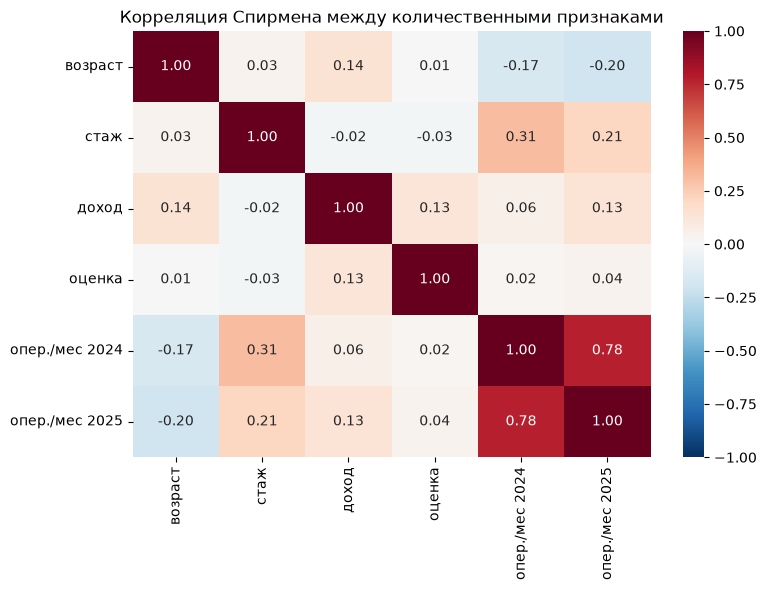

In [34]:
# изменение активности: операций на клиента в месяц, I пол. 2025 к 2024
cl = clients.set_index("client_id").join(per[["операций в месяц, 2024", "операций в месяц, I пол. 2025"]], how="inner")

def change_by(col):
    t = cl.groupby(col, observed=True)[["операций в месяц, 2024", "операций в месяц, I пол. 2025"]].mean()
    t["изменение, %"] = (t.iloc[:, 1] / t.iloc[:, 0] - 1) * 100
    t.insert(0, "клиентов", cl.groupby(col, observed=True).size())
    return t.round(1)

total = (cl["операций в месяц, I пол. 2025"].mean() / cl["операций в месяц, 2024"].mean() - 1) * 100
show(pd.concat({col: change_by(col) for col in ["segment", "loyalty_tier", "card_type", "city", "income_source",
                                                "has_mobile_app", "marketing_opt_in", "gender"]}, names=["разрез", "значение"]),
     f"Операций на клиента в месяц по разрезам (в среднем по всем: {total:+.1f} %)")

cl["возрастная группа"] = pd.cut(cl["age"], [18, 30, 45, 60, 100], labels=["до 30", "30–44", "45–59", "60+"], right=False)
cl["доход"] = pd.qcut(cl["monthly_income"], 4, labels=["Q1 (низкий)", "Q2", "Q3", "Q4 (высокий)"])
show(pd.concat({col: change_by(col) for col in ["возрастная группа", "доход"]}, names=["разрез", "значение"]),
     "Операций на клиента в месяц: возраст и доход (доход — квартили, без пропусков)")

# то же графиком: изменение по каждому разрезу, пунктир — среднее по всем клиентам
slices = ["segment", "loyalty_tier", "card_type", "city", "income_source", "has_mobile_app", "возрастная группа", "доход"]
NAMES = {"segment": "Сегмент", "loyalty_tier": "Уровень лояльности", "card_type": "Тип карты", "city": "Город",
         "income_source": "Источник зарплаты", "has_mobile_app": "Приложение", "возрастная группа": "Возраст", "доход": "Доход (квартили)"}
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True)          # общая шкала — разрезы сравнимы между собой
for ax, col in zip(axes.flat, slices):
    t = change_by(col)["изменение, %"]
    t.index = t.index.map(lambda v: {True: "Да", False: "Нет"}.get(v, v))
    t.sort_values(ascending=False).plot.barh(ax=ax, color=["tab:red" if v < total else "tab:grey" for v in t.sort_values(ascending=False)])
    ax.axvline(total, color="black", ls="--", lw=1)
    ax.set(title=NAMES[col], xlabel="изменение операций на клиента, %", ylabel="")
plt.suptitle(f"Изменение операций на клиента в месяц, I пол. 2025 к 2024 (пунктир — в среднем {total:+.1f} %; красным — хуже среднего)")
plt.tight_layout(); plt.show()

# по категориям и каналам: доля операций в базе и в оценке
for col in ["category", "channel"]:
    t = txn_act.groupby([col, "period"]).size().unstack()
    t = t.assign(base=t["base"] / 12, eval=t["eval"] / 6)
    t["изменение, %"] = (t["eval"] / t["base"] - 1) * 100
    show(t.rename(columns={"base": "в месяц, 2024", "eval": "в месяц, I пол. 2025"}).round(1).sort_values("изменение, %"),
         f"Операций в месяц по {'категориям' if col == 'category' else 'каналам'}")

# связи между количественными признаками (Спирмен — устойчив к скошенности)
corr_cols = ["age", "tenure", "monthly_income", "satisfaction_score", "операций в месяц, 2024", "операций в месяц, I пол. 2025"]
corr = cl[corr_cols].corr(method="spearman").rename(index=dict(zip(corr_cols, ["возраст", "стаж", "доход", "оценка", "опер./мес 2024", "опер./мес 2025"])))
corr.columns = corr.index
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Корреляция Спирмена между количественными признаками")
plt.tight_layout(); plt.show()

**Что видно в 5.4** (изменение операций на клиента в месяц, I пол. 2025 к 2024; в среднем −17,0 %; расчёт простой, как в 5.1 — точная метрика в разделе 6)
- **Сегмент:** «Массовый» −30 %, остальные −6…−11 %.
- **Город:** Новосибирск −26 %, остальные −14…−16 %.
- **Приложение:** без приложения −24 %, с приложением −13 %.
- **Возраст и доход:** 60+ −23 % против −6…−16 % у остальных; нижний квартиль дохода −23 % против −9 % у верхнего.
- **Источник зарплаты:** «у нас» −12 %, «в другом банке» −21 %, «Не указан» −23 %.
- **Категории:** сильнее всего «Кафе и рестораны» (−28 %), остальные −13…−17 %.
- **Каналы:** «Токен» +30 %, «Карта» −27 %, «Онлайн-банк» −30 % — поэтому метрику считаем по всем каналам: иначе переход на оплату телефоном выглядел бы как падение.
- **Связи:** активность 2024 и 2025 связана сильно (ρ = 0,77), со стажем — слабо (0,31 и 0,21; часть связи искусственная: у недавно открывших карту база за 2024 занижена делением на 12), с возрастом — слабо отрицательно; доход и оценка почти не связаны с активностью.

Разрезы пересекаются (Массовый, Базовый уровень, низкий доход, нет приложения — во многом одни и те же клиенты). Какой признак объясняет падение сам по себе, проверяем в разделе 7.

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

**Метрика активности — число успешных операций в месяц по всем каналам** (Карта, Токен, СБП, Онлайн-банк).

- **Изменение у клиента** = среднее в месяц за янв–июн 2025 / среднее в месяц за 2024 − 1.
- **Только успешные операции:** отклонённая операция не состоялась, возврат — отмена покупки, а не новая активность.
- **Все каналы:** «Токен» вырос на 30 %, «Карта» упала на 27 % (5.4) — переход на оплату телефоном не должен выглядеть как падение.
- **Число операций, а не сумма:** задача — вернуть привычку пользоваться картой; на сумму сильно влияют единичные крупные покупки, а для EUR/USD нет курса.
- **База — 2024 год**, как в задании, но только месяцы, когда текущая карта уже открыта (с первого полного месяца): операций до открытия карты в данных нет (2.4, 5.1). Клиентов с базой короче 3 месяцев не оцениваем — сравнивать не с чем.


### 6.1. Метрика A на клиента

**На ком считается метрика**

,клиентов
клиентов в справочнике,5667
база короче 3 мес. (карта открыта поздно),567
в базе ни одной операции,1
метрику можно посчитать,5099


**Метрика A на 5099 клиентах**

,метрика A
"операций в месяц, база (медиана)",5.8
"операций в месяц, I пол. 2025 (медиана)",4.2
"изменение у клиента, медиана, %",-20.9
"изменение суммарно, %",-20.3
клиентов с падением,3653.0
клиентов с ростом или без изменений,1446.0


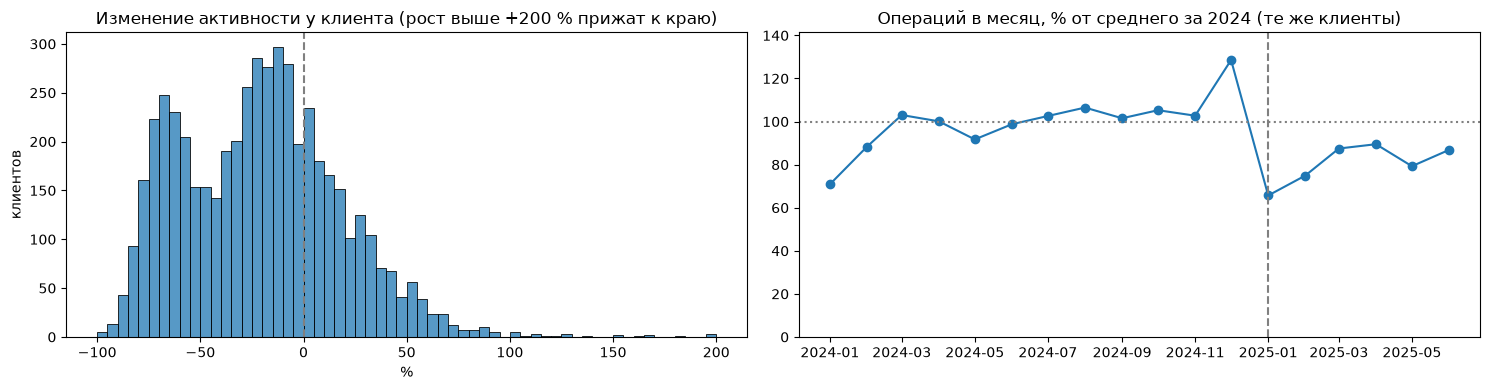

In [35]:
# --- 6.1. метрика A: успешных операций в месяц по всем каналам, I пол. 2025 к 2024 ---
MONTHS = pd.period_range(D_START, D_END - pd.Timedelta(days=1), freq="M")      # 2024-01 … 2025-06
BASE = MONTHS[MONTHS.year == 2024]
EVAL = MONTHS[MONTHS.year == 2025]
MIN_BASE_MONTHS = 3

cl = clients.set_index("client_id")
# первый полный месяц с текущей картой: операций до открытия карты в данных нет (2.4, 5.1)
first_month = cl["card_open_date"].dt.to_period("M")
first_month = first_month.where(cl["card_open_date"].dt.day == 1, first_month + 1).clip(lower=MONTHS[0])
avail = pd.DataFrame({m: first_month <= m for m in MONTHS})                    # месяц учитывается для клиента

month_of = txn_act["txn_datetime"].dt.to_period("M")
ops = (txn_act.groupby(["client_id", month_of]).size().unstack(fill_value=0)
              .reindex(index=cl.index, columns=MONTHS, fill_value=0))

def per_month(table, months):
    """Среднее в месяц по доступным месяцам и число таких месяцев."""
    a = avail[months]
    n = a.sum(axis=1)
    return (table[months] * a).sum(axis=1) / n.replace(0, np.nan), n

act = pd.DataFrame(index=cl.index)
act["ops_base"], act["base_months"] = per_month(ops, BASE)
act["ops_eval"], act["eval_months"] = per_month(ops, EVAL)
act["measurable"] = (act["base_months"] >= MIN_BASE_MONTHS) & (act["eval_months"] == len(EVAL)) & (act["ops_base"] > 0)
act["change_A"] = np.where(act["measurable"], act["ops_eval"] / act["ops_base"] - 1, np.nan)

coverage = pd.DataFrame({"клиентов": [
    len(act),
    (act["base_months"] < MIN_BASE_MONTHS).sum(),
    ((act["base_months"] >= MIN_BASE_MONTHS) & (act["eval_months"] == len(EVAL)) & (act["ops_base"] == 0)).sum(),
    act["measurable"].sum(),
]}, index=["клиентов в справочнике", f"база короче {MIN_BASE_MONTHS} мес. (карта открыта поздно)",
           "в базе ни одной операции", "метрику можно посчитать"])
show(coverage, "На ком считается метрика")

m = act[act["measurable"]]
show(pd.DataFrame({
    "операций в месяц, база (медиана)": [m["ops_base"].median()],
    "операций в месяц, I пол. 2025 (медиана)": [m["ops_eval"].median()],
    "изменение у клиента, медиана, %": [m["change_A"].median() * 100],
    "изменение суммарно, %": [(m["ops_eval"].sum() / m["ops_base"].sum() - 1) * 100],
    "клиентов с падением": [(m["change_A"] < 0).sum()],
    "клиентов с ростом или без изменений": [(m["change_A"] >= 0).sum()],
}).round(1).T.rename(columns={0: "метрика A"}), f"Метрика A на {len(m)} клиентах")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(m["change_A"].clip(upper=2) * 100, bins=60, ax=ax[0])
ax[0].axvline(0, color="grey", ls="--")
ax[0].set(title="Изменение активности у клиента (рост выше +200 % прижат к краю)", xlabel="%", ylabel="клиентов")
idx = (ops.loc[m.index].sum() / ops.loc[m.index, BASE].sum(axis=1).sum() * len(BASE)) * 100
ax[1].plot(MONTHS.to_timestamp(), idx, marker="o")
ax[1].axhline(100, color="grey", ls=":"); ax[1].axvline(B_END, color="grey", ls="--")
ax[1].set(title="Операций в месяц, % от среднего за 2024 (те же клиенты)", xlabel="месяц", ylabel="% от среднего за 2024", ylim=(0, idx.max() * 1.1))
plt.tight_layout(); plt.show()

В метрике 5 099 клиентов из 5 667: у 567 карта открыта слишком поздно (база короче 3 месяцев), у 1 нет ни одной операции в базе. Медиана изменения −20,9 %, активность снизилась у 72 % клиентов.

Распределение изменений **двугорбое**: одна группа клиентов около −15 % (общее снижение), вторая около −70 % (активность почти ушла). Это и есть материал для групп в разделе 7 — нужно понять, кто эти клиенты во втором «горбе».

### 6.2. Проверки чувствительности

In [36]:
# --- 6.2. чувствительность: другая база (B) и деньги вместо числа операций (C) ---
BASE_H1 = BASE[BASE.month <= 6]
b_h1, n_h1 = per_month(ops, BASE_H1)
ok_B = (n_h1 >= MIN_BASE_MONTHS) & (act["eval_months"] == len(EVAL)) & (b_h1 > 0)
act["change_B"] = np.where(ok_B, act["ops_eval"] / b_h1 - 1, np.nan)

rub = (txn_act[txn_act["currency"] == "RUB"].groupby(["client_id", month_of]).agg({"amount": "sum"})["amount"]
       .unstack(fill_value=0).reindex(index=cl.index, columns=MONTHS, fill_value=0))
rub_base, _ = per_month(rub, BASE)
rub_eval, _ = per_month(rub, EVAL)
act["change_C"] = np.where(act["measurable"] & (rub_base > 0), rub_eval / rub_base - 1, np.nan)

rows = []
for col, name in [("change_A", "A: операции, база 2024 (основная)"), ("change_B", "B: операции, база I пол. 2024"),
                  ("change_C", "C: траты в RUB, база 2024")]:
    s = act[col].dropna()
    rows.append((name, len(s), s.median() * 100, (s < 0).mean() * 100))
sens = pd.DataFrame(rows, columns=["метрика", "клиентов", "изменение, медиана, %", "доля с падением, %"]).set_index("метрика")
show(sens.round(1), "Метрика A и проверки чувствительности")

both = act[["change_A", "change_B", "change_C"]].dropna()
corr = both.corr(method="spearman").round(2)
corr.index = corr.columns = ["A", "B", "C"]
show(corr, f"Согласованность метрик: корреляция Спирмена по клиентам ({len(both)} клиентов, у кого считаются все три)")

**Метрика A и проверки чувствительности**

,клиентов,"изменение, медиана, %","доля с падением, %"
метрика,,,
"A: операции, база 2024 (основная)",5099,-20.9,71.6
"B: операции, база I пол. 2024",4840,-14.5,63.1
"C: траты в RUB, база 2024",5099,-34.3,74.1


**Согласованность метрик: корреляция Спирмена по клиентам (4840 клиентов, у кого считаются все три)**

,A,B,C
A,1.00,0.96,0.78
B,0.96,1.00,0.75
C,0.78,0.75,1.00


**Устойчивость:**
- При базе «I полугодие 2024» (без декабрьского пика) медиана −14,5 % вместо −20,9 %: около 6 п.п. падения по метрике A — сезонность. В отчёте даём обе цифры.
- Порядок клиентов почти не меняется: корреляция A и B — 0,96. Значит, для **выбора групп** A годится.
- По тратам в рублях (C) падение тоже есть (медиана −34 %), согласованность с A — 0,78: те, у кого упало число операций, в основном тратят и меньше.

### 6.3. Характер падения и что метрика не видит

**Характер падения: сколько клиентов под каждый признак**

,клиентов,из
в мае–июне меньше 20 % базы (сошла на нет),692,5099
ни одного месяца 2025 на уровне ≥ 50 % базы,258,5099
доля «Карты» упала на ≥ 20 п.п.,656,5099
доля «Токена» выросла на ≥ 20 п.п.,540,5099


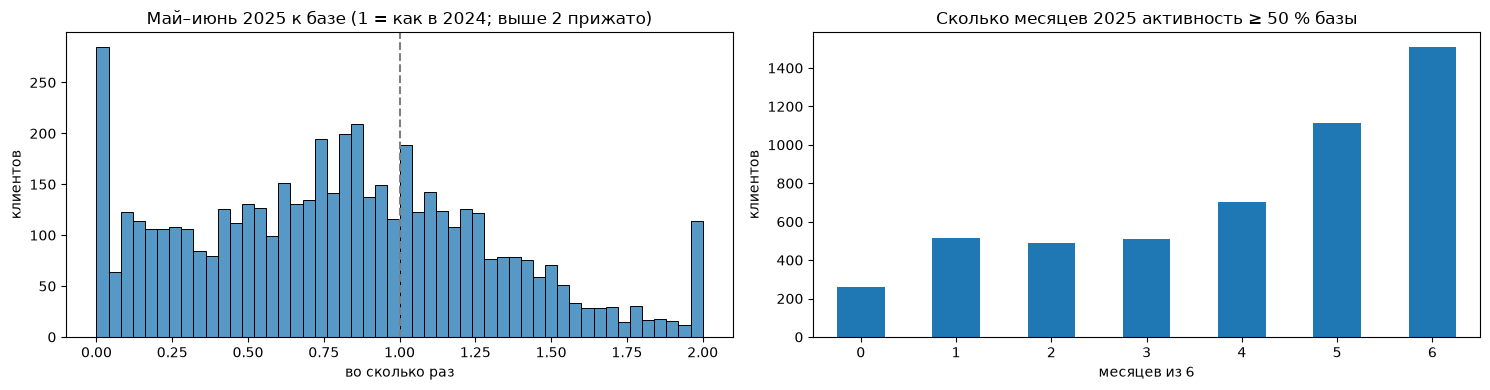

In [37]:
# --- 6.3. характер падения: признаки на клиента для второй части правила групп ---
LATE = EVAL[-2:]                                                                  # май–июнь 2025
late, _ = per_month(ops, LATE)
act["late_ratio"] = np.where(act["measurable"], late / act["ops_base"], np.nan)  # конец периода к базе

# месяцев 2025, в которых операций не меньше половины базы — «держится» или «обрыв»
ratio_m = ops[EVAL].div(act["ops_base"], axis=0)
act["eval_months_ok"] = np.where(act["measurable"], (ratio_m >= 0.5).sum(axis=1), np.nan)

# сдвиг между каналами и категориями: доля в базе и в оценке (операций клиента)
def share_shift(col):
    t = txn_act.assign(period=np.where(month_of.isin(BASE), "base", "eval"))
    cnt = t.groupby(["client_id", "period", col]).size().unstack([1, 2], fill_value=0)
    out = {}
    for v in t[col].unique():
        base = cnt.get(("base", v), 0) / cnt.xs("base", axis=1, level=0).sum(axis=1)
        ev = cnt.get(("eval", v), 0) / cnt.xs("eval", axis=1, level=0).sum(axis=1)
        out[v] = (ev - base).reindex(cl.index)
    return pd.DataFrame(out)

ch_shift = share_shift("channel").add_prefix("доля канала Δ: ")
act = act.join(ch_shift)
act["C_vs_A"] = act["change_C"] - act["change_A"]                                # >0: операций меньше, но суммы держатся

m = act[act["measurable"]]
show(pd.DataFrame({
    "в мае–июне меньше 20 % базы (сошла на нет)": [(m["late_ratio"] < 0.2).sum()],
    "ни одного месяца 2025 на уровне ≥ 50 % базы": [(m["eval_months_ok"] == 0).sum()],
    "доля «Карты» упала на ≥ 20 п.п.": [(m["доля канала Δ: Карта"] <= -0.2).sum()],
    "доля «Токена» выросла на ≥ 20 п.п.": [(m["доля канала Δ: Токен"] >= 0.2).sum()],
}, index=["клиентов"]).T.assign(**{"из": len(m)}), "Характер падения: сколько клиентов под каждый признак")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(m["late_ratio"].clip(upper=2), bins=50, ax=ax[0])
ax[0].axvline(1, color="grey", ls="--")
ax[0].set(title="Май–июнь 2025 к базе (1 = как в 2024; выше 2 прижато)", xlabel="во сколько раз", ylabel="клиентов")
m["eval_months_ok"].astype(int).value_counts().sort_index().plot.bar(ax=ax[1], rot=0)
ax[1].set(title="Сколько месяцев 2025 активность ≥ 50 % базы", xlabel="месяцев из 6", ylabel="клиентов")
plt.tight_layout(); plt.show()

facts["metric_clients"] = int(act["measurable"].sum())
facts["metric_change_A_median"] = round(float(m["change_A"].median() * 100), 1)
facts["metric_change_B_median"] = round(float(act["change_B"].median() * 100), 1)

**Характер падения** — признаки для второй части правила группы («что с ними произошло»):
- **сошла на нет к концу периода** — операций в мае–июне меньше 20 % базы: 692 клиента;
- **не держится ни одного месяца** — ни в одном месяце 2025 не набрано 50 % базы: 258 клиентов;
- **ушёл с карты** — доля «Карты» в операциях упала на 20 п.п. и больше: 656 клиентов;
- **перешёл на телефон** — доля «Токена» выросла на 20 п.п. и больше: 540 клиентов (это не падение, а смена способа оплаты).

Пороги здесь — только уточнения к описанию; само правило группы будет «кто это + что произошло» (раздел 7).

**Чего метрика не увидит:**
- **клиентов вне справочника** — 333 клиента с операциями, которых нет в справочнике действующих на 30.06.2025 (2.4);
- **клиентов с короткой историей** — 567 человек с картой, открытой после сентября 2024;
- **«так же часто, но меньше»** — если число операций то же, а суммы упали (для этого есть проверка C);
- **падения в самом конце периода** — если клиент перестал платить только в июне, среднее за полгода размоет падение (частично ловит признак «сошла на нет»);
- **переноса оплат в другой банк** — в данных только наши операции, и это выглядит как обычное снижение;
- **сезонность внутри года** — декабрь в базе и январь в оценке завышают падение примерно на 6 п.п. (см. проверку B).

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

**Как устроено правило группы.** Каждая группа = **кто это** (сегмент, наличие приложения, характер трат) + **что с ними произошло** (характер падения). Пороги ниже — только уточнения ко второй части, а не само правило.

**Кого рассматриваем:** метрика считается (база ≥ 3 мес.), есть согласие на маркетинг, сегмент надёжен (нет двух версий строки, 3.1). Кто не прошёл — в 7.1.

**Правило конфликтов:** клиент идёт в первую по порядку группу. G1/G2 и G3/G4 не пересекаются по сегменту; G3 и G4 пересекаются — тогда G3, потому что у неё причина конкретнее (ушли из одной категории).

In [38]:
# --- признаки клиента для правил групп: всё считается из тех же двух таблиц ---
period = np.where(month_of.isin(BASE), "base", "eval")

def per_month_by(col, value):
    """Операций в месяц с данным значением поля: в базе (по доступным месяцам) и в оценке."""
    hit = txn_act[col] == value
    cnt = (txn_act[hit].groupby(["client_id", period[hit]]).size().unstack(fill_value=0)
                        .reindex(index=cl.index, columns=["base", "eval"], fill_value=0))
    return cnt["base"] / act["base_months"].replace(0, np.nan), cnt["eval"] / len(EVAL)

cafe_b, cafe_e = per_month_by("category", "Кафе и рестораны")
card_b, card_e = per_month_by("channel", "Карта")
tok_b, tok_e = per_month_by("channel", "Токен")

feat = act[["measurable", "change_A", "late_ratio", "ops_base", "ops_eval"]].join(
    cl[["segment", "has_mobile_app", "marketing_opt_in", "conflict", "city", "loyalty_tier", "card_type"]])
feat["age"] = (REF_DATE - cl["birth_date"]).dt.days / 365.25
feat["cafe_share_base"] = cafe_b / act["ops_base"]                       # доля кафе в операциях базы
feat["cafe_change"] = cafe_e / cafe_b.replace(0, np.nan) - 1
feat["other_change"] = (act["ops_eval"] - cafe_e) / (act["ops_base"] - cafe_b).replace(0, np.nan) - 1   # всё, кроме кафе
feat["card_change"] = card_e / card_b.replace(0, np.nan) - 1
feat["token_delta"] = tok_e - tok_b                                      # +: оплат телефоном в месяц стало больше
# вернулся ли клиент после январского провала: март–июнь 2025 к базе
SPRING = EVAL[EVAL.month >= 3]
feat["spring_ratio"] = (ops[SPRING] * avail[SPRING]).sum(axis=1) / len(SPRING) / act["ops_base"]

# пороги правил — уточнения ко второй части правила («что произошло»), не само правило
DROP = -0.30            # активность (метрика A) упала не меньше чем на 30 %
NOT_BACK = 0.70        # в марте–июне меньше 70 % базы — не вернулись после январского провала
CAFE_SHARE = 0.20       # кафе — не меньше 20 % операций в базе (медиана по клиентам — 12 %)
CAFE_DROP = -0.50       # операций в кафе стало вдвое меньше
show(pd.DataFrame({"порог": [DROP, NOT_BACK, CAFE_SHARE, CAFE_DROP]},
                  index=["падение активности (A)", "март–июнь к базе", "доля кафе в базе", "падение операций в кафе"]),
     "Пороги-уточнения в правилах групп")

**Пороги-уточнения в правилах групп**

,порог
падение активности (A),-0.3
март–июнь к базе,0.7
доля кафе в базе,0.2
падение операций в кафе,-0.5


In [39]:
# --- правила групп: «кто это» + «что с ними произошло» ---
mass = feat["segment"] == "Массовый"
app = feat["has_mobile_app"]
dropped = feat["change_A"] <= DROP
cafe_lover = (feat["cafe_share_base"] >= CAFE_SHARE) & (feat["cafe_change"] <= CAFE_DROP)

# порядок важен: при пересечении клиент идёт в первую подходящую группу
RULES = {
    "G1 Массовый без приложения: обвал с января": mass & ~app & dropped,
    "G2 Массовый с приложением: обвал с января, приложение не удержало": mass & app & dropped,
    "G3 Немассовые любители кафе: перестали ходить в кафе": ~mass & cafe_lover,
    "G4 Немассовые: не вернулись после январского провала": ~mass & dropped & (feat["spring_ratio"] < NOT_BACK),
}
# в кампанию — только те, у кого метрика считается, есть согласие на маркетинг и надёжный сегмент
eligible = feat["measurable"] & feat["marketing_opt_in"] & ~feat["conflict"]
match = pd.DataFrame({name: rule & eligible for name, rule in RULES.items()}).fillna(False)

# правило конфликтов: клиент идёт в первую по порядку группу (G3 раньше G4: у G3 причина конкретнее)
show(match.T.dot(match.astype(int)).astype(int), "Пересечения групп до разрешения конфликтов (по диагонали — размер группы)")
feat["group"] = match.idxmax(axis=1).where(match.any(axis=1))

sizes = feat.groupby("group").agg(клиентов=("change_A", "size"), падение_медиана_проц=("change_A", "median"),
                                  май_июнь_к_базе_медиана=("late_ratio", "median"))
sizes["падение_медиана_проц"] = (sizes["падение_медиана_проц"] * 100).round(1)
show(sizes.round(2), f"Группы: всего {sizes['клиентов'].sum()} клиентов")
assert sizes["клиентов"].min() >= MIN_GROUP, "есть группа меньше 150"
assert sizes["клиентов"].sum() <= BUDGET, "превышен бюджет 2000"

**Пересечения групп до разрешения конфликтов (по диагонали — размер группы)**

,G1 Массовый без приложения: обвал с января,"G2 Массовый с приложением: обвал с января, приложение не удержало",G3 Немассовые любители кафе: перестали ходить в кафе,G4 Немассовые: не вернулись после январского провала
G1 Массовый без приложения: обвал с января,617,0,0,0
"G2 Массовый с приложением: обвал с января, приложение не удержало",0,642,0,0
G3 Немассовые любители кафе: перестали ходить в кафе,0,0,344,148
G4 Немассовые: не вернулись после январского провала,0,0,148,441


**Группы: всего 1896 клиентов**

,клиентов,падение_медиана_проц,май_июнь_к_базе_медиана
group,,,
G1 Массовый без приложения: обвал с января,617,-64.9,0.23
"G2 Массовый с приложением: обвал с января, приложение не удержало",642,-60.0,0.36
G3 Немассовые любители кафе: перестали ходить в кафе,344,-31.3,0.70
G4 Немассовые: не вернулись после январского провала,293,-60.0,0.34


**Профиль групп (клиенты, у которых считается метрика)**

,клиентов,возраст_медиана,с_приложением_проц,Базовый_уровень_проц,падение_кафе_медиана,падение_прочего_медиана,падение_картой_медиана,Токен_в_месяц_прирост,март_июнь_к_базе
group,,,,,,,,,
G1 Массовый без приложения: обвал с января,617,59.17,0.00,70.66,-0.75,-0.65,-0.64,-0.17,0.32
"G2 Массовый с приложением: обвал с января, приложение не удержало",642,49.20,100.00,71.34,-0.71,-0.60,-0.62,-0.33,0.40
G3 Немассовые любители кафе: перестали ходить в кафе,344,51.39,59.01,24.42,-0.89,-0.11,-0.33,-0.17,0.71
G4 Немассовые: не вернулись после январского провала,293,54.74,48.12,36.52,-0.61,-0.60,-0.63,-0.25,0.42
не в кампании,3203,51.14,65.25,47.39,-0.08,-0.03,-0.07,0.00,1.03


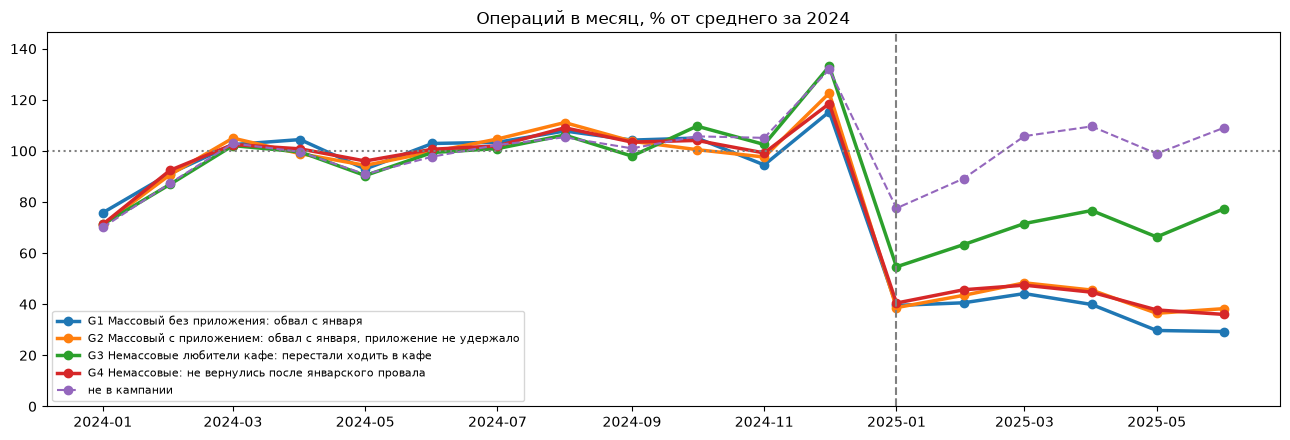

**Изменение операций в месяц по категориям, I пол. 2025 к 2024, %**

category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
grp,,,,,,,,,
G1 Массовый без приложения: обвал с января,-66.0,-64.0,-68.0,-59.0,-61.0,-62.0,-63.0,-61.0,-63.0
"G2 Массовый с приложением: обвал с января, приложение не удержало",-54.0,-59.0,-67.0,-61.0,-54.0,-56.0,-59.0,-60.0,-58.0
G3 Немассовые любители кафе: перестали ходить в кафе,-16.0,-13.0,-85.0,-17.0,-12.0,-9.0,-13.0,-10.0,-10.0
G4 Немассовые: не вернулись после январского провала,-57.0,-57.0,-56.0,-59.0,-57.0,-59.0,-62.0,-54.0,-59.0
не в кампании,-0.0,-1.0,-6.0,-1.0,-1.0,-1.0,-0.0,-2.0,-2.0


**Изменение операций в месяц по каналам, I пол. 2025 к 2024, %**

channel,Карта,Онлайн-банк,СБП,Токен
grp,,,,
G1 Массовый без приложения: обвал с января,-62.0,-68.0,-61.0,-62.0
"G2 Массовый с приложением: обвал с января, приложение не удержало",-60.0,-63.0,-57.0,-51.0
G3 Немассовые любители кафе: перестали ходить в кафе,-32.0,-43.0,-30.0,-17.0
G4 Немассовые: не вернулись после январского провала,-59.0,-66.0,-56.0,-48.0
не в кампании,-16.0,-15.0,-1.0,63.0


In [40]:
# --- за счёт чего упала активность: профиль, динамика, категории и каналы по группам ---
grp = feat["group"].fillna("не в кампании")
in_metric = feat["measurable"]
prof = feat[in_metric].groupby(grp[in_metric]).agg(
    клиентов=("age", "size"), возраст_медиана=("age", "median"),
    с_приложением_проц=("has_mobile_app", "mean"), Базовый_уровень_проц=("loyalty_tier", lambda s: (s == "Базовый").mean()),
    падение_кафе_медиана=("cafe_change", "median"), падение_прочего_медиана=("other_change", "median"),
    падение_картой_медиана=("card_change", "median"), Токен_в_месяц_прирост=("token_delta", "median"),
    март_июнь_к_базе=("spring_ratio", "median"))
for c in ["с_приложением_проц", "Базовый_уровень_проц"]:
    prof[c] = prof[c] * 100
show(prof.round(2), "Профиль групп (клиенты, у которых считается метрика)")

# помесячная динамика: операций в месяц, % от среднего за 2024 — по группам
idx = ops.loc[in_metric].groupby(grp[in_metric]).sum()
idx = idx.div(idx[BASE].mean(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, row in idx.iterrows():
    ax.plot(MONTHS.to_timestamp(), row, marker="o", label=name, lw=2.5 if name != "не в кампании" else 1.5,
            ls="-" if name != "не в кампании" else "--")
ax.axhline(100, color="grey", ls=":"); ax.axvline(B_END, color="grey", ls="--")
ax.set(title="Операций в месяц по группам, % от среднего за 2024", xlabel="месяц", ylabel="% от среднего за 2024", ylim=(0, idx.max().max() * 1.1))
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

# изменение по категориям и каналам внутри групп, %
def change_table(col):
    t = txn_act.assign(grp=txn_act["client_id"].map(grp), period=period)
    t = t[t["client_id"].isin(feat.index[in_metric])]
    c = t.groupby(["grp", col, "period"]).size().unstack()
    return ((c["eval"] / len(EVAL)) / (c["base"] / len(BASE)) - 1).mul(100).round(0).unstack(col)
show(change_table("category"), "Изменение операций в месяц по категориям, I пол. 2025 к 2024, %")
show(change_table("channel"), "Изменение операций в месяц по каналам, I пол. 2025 к 2024, %")

**Группы**

| группа | кто | что произошло | клиентов |
|---|---|---|---|
| **G1** | «Массовый» сегмент без мобильного приложения | с января 2025 активность упала примерно до трети базы и не восстановилась (медиана −65 %, март–июнь — 32 % базы); падение одинаковое во всех категориях (−59…−68 %) и каналах | 617 |
| **G2** | «Массовый» сегмент с приложением | то же резкое падение с января (медиана −60 %, март–июнь — 40 % базы) во всех категориях; оплата телефоном («Токен») тоже упала (−51 %) — приложение не удержало | 642 |
| **G3** | клиенты остальных сегментов, у которых кафе и рестораны — не меньше 20 % операций | перестали ходить в кафе (−85 % операций в кафе), остальные траты почти не изменились (−9…−17 %, как у всех — сезонность) | 344 |
| **G4** | клиенты остальных сегментов («Зарплатный», «Премиальный», Private) | не вернулись после январского провала: у остальных клиентов этих сегментов к марту активность восстановилась до уровня 2024, у этих — 42 % базы; падение во всех категориях (−55…−62 %) | 293 |

**За счёт чего упала активность**
- **G1 и G2** — не одна категория и не один канал, а общий отказ от карты: все категории и каналы падают одинаково. Различие — в канале связи: у G1 нет приложения (возраст медиана 59), у G2 оно есть, но не помогло (медиана 49).
- **G3** — точечный уход из одной категории при сохранении остальных трат.
- **G4** — та же картина, что у G1/G2, но в сегментах, где у остальных клиентов падения почти нет.

Почему клиенты так себя повели (например, перевели траты в другой банк), по нашим данным не видно — в данных только операции по нашим картам.

**Как на группы воздействовать.** Группы разделены так, чтобы у каждой был свой канал связи и свой повод для разговора. Канал взят из данных, предложение — гипотеза кампании (данными не проверяется).

| группа | смысл | канал связи (из данных) | что предложить (гипотеза) |
|---|---|---|---|
| G1 | вернуть к карте целиком и дать цифровой канал | СМС, звонок, отделение — приложения нет ни у кого | напоминание о карте, предложение установить приложение, бонус за первые операции |
| G2 | приложение есть, но не удержало | пуш в приложении — приложение у всех | персональное предложение на повседневные траты, напоминание об оплате телефоном |
| G3 | ушли только из кафе | пуш (203 с приложением) или СМС/звонок (141 без) | кешбэк или акция в кафе и ресторанах |
| G4 | более ценные сегменты, не вернувшиеся после января | пуш (141) или СМС/звонок (152); «Премиальный» и Private — через менеджера | личный контакт, выяснить причину, предложить условия |

### 7.1. Кого в кампанию не берём и почему

In [41]:
# --- 7.1. кого не берём: воронка от всех клиентов справочника до списка кампании ---
steps = [
    ("клиентов в справочнике", pd.Series(True, index=feat.index)),
    ("метрика считается (база ≥ 3 мес.)", feat["measurable"]),
    ("есть согласие на маркетинг", feat["marketing_opt_in"]),
    ("сегмент надёжен (нет двух версий строки)", ~feat["conflict"]),
    ("подходит под правило группы", feat["group"].notna()),
]
keep = pd.Series(True, index=feat.index)
rows = []
for name, cond in steps:
    before = keep.sum()
    keep &= cond
    rows.append((name, keep.sum(), before - keep.sum()))
excl = pd.DataFrame(rows, columns=["шаг", "осталось клиентов", "не взяли"]).set_index("шаг")
show(excl, "Кого не берём в кампанию")

# кто из снизивших активность не попал ни в одну группу — и почему
left = feat["measurable"] & feat["marketing_opt_in"] & ~feat["conflict"] & feat["group"].isna() & (feat["change_A"] <= DROP)
show(feat[left].groupby("segment").agg(клиентов=("change_A", "size"), падение_медиана=("change_A", "median"))
     .assign(падение_медиана=lambda t: (t["падение_медиана"] * 100).round(1)),
     f"Снизили активность на ≥ 30 %, но не в группах: {left.sum()} клиентов")

campaign = feat.loc[feat["group"].notna(), ["group"]].reset_index()
assert campaign["client_id"].is_unique and len(campaign) <= BUDGET
facts["campaign_size"] = len(campaign)
facts["groups"] = campaign["group"].value_counts().to_dict()

**Кого не берём в кампанию**

,осталось клиентов,не взяли
шаг,,
клиентов в справочнике,5667,0
метрика считается (база ≥ 3 мес.),5099,568
есть согласие на маркетинг,4457,642
сегмент надёжен (нет двух версий строки),4444,13
подходит под правило группы,1896,2548


**Снизили активность на ≥ 30 %, но не в группах: 59 клиентов**

,клиентов,падение_медиана
segment,,
Private,7,-34.5
Зарплатный,38,-33.3
Премиальный,14,-33.3


**Кого не берём и почему**
- **568 клиентов — метрику не посчитать:** карта открыта после сентября 2024, базы меньше 3 месяцев; сравнивать не с чем.
- **642 — нет согласия на маркетинговую коммуникацию** (): по условию задачи коммуникация возможна только с согласия клиента.
- **13 — две версии строки в справочнике** (разный сегмент или город, 3.1): правило по сегменту к ним применить надёжно нельзя.
- **2 548 — не подходят ни под одно правило:** в основном у них активность не упала (у остальных клиентов медиана изменения около нуля к I пол. 2024). 59 человек снизили активность на 30 % и больше, но к весне вернулись (март–июнь ≥ 70 % базы) — возвращать их не нужно.
- **333 клиента, которых нет в справочнике действующих** (2.4), в расчёт не входили: в кампанию берём только действующих клиентов.

Итого в кампании **1 896 клиентов** — меньше бюджета 2 000. Остаток не добираем искусственно: остальные кандидаты либо не снизили активность, либо их нельзя взять.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [42]:
# гипотезы о причинах падения: проверяем на клиентах, у которых считается метрика
h = feat[feat["measurable"]].join(cl[["income_source", "gender", "monthly_income"]])
hm = h[h["segment"] == "Массовый"]
med = lambda s: round(s.median() * 100, 1)                                   # медиана изменения, %
dated = (~txn_act["has_time"]).groupby(month_of).mean() * 100
hm_q = pd.qcut(hm["monthly_income"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
dropped_h = h["change_A"] <= DROP

hyp = pd.DataFrame([
    ("Новосибирск падает сильнее из-за города",
     f"внутри «Массового»: Новосибирск {med(hm.loc[hm['city'] == 'Новосибирск', 'change_A'])} %, "
     f"другие города {med(hm.loc[hm['city'] != 'Новосибирск', 'change_A'])} %; "
     f"«Массовых» в Новосибирске {(h.loc[h['city'] == 'Новосибирск', 'segment'] == 'Массовый').mean():.0%} против {(h['segment'] == 'Массовый').mean():.0%} в среднем",
     "не подтвердилась: разница — от доли «Массового» сегмента"),
    ("Зарплата в нашем банке удерживает активность",
     f"внутри «Массового»: «у нас» {med(hm.loc[hm['income_source'] == 'Зарплата в нашем банке', 'change_A'])} %, "
     f"«в другом банке» {med(hm.loc[hm['income_source'] == 'Зарплата в другом банке', 'change_A'])} %",
     "не подтвердилась: общая разница — от состава сегментов"),
    ("Падение — это переход на оплату телефоном",
     f"у снизивших на ≥ 30 % операций «Токеном» в месяц стало больше только у {(h.loc[dropped_h, 'token_delta'] > 0).mean():.0%}; "
     f"«Токен» падает и в группах G1, G2, G4",
     "не подтвердилась для снизивших; переход на телефон есть у остальных клиентов"),
    ("Всё падение — сезонность (декабрь в базе)",
     f"к I пол. 2024: «Массовый» {med(act.loc[hm.index, 'change_B'])} %, остальные {med(act.loc[h.index[h['segment'] != 'Массовый'], 'change_B'])} %",
     "не подтвердилась для «Массового»; у остальных сегментов — почти только сезонность"),
    ("Падение — артефакт данных (операции без времени)",
     f"доля операций без времени по месяцам {dated.min():.1f}–{dated.max():.1f} %, одинакова до и после января",
     "не подтвердилась"),
    ("Падают клиенты с низким доходом",
     f"внутри «Массового»: Q1 дохода {med(hm.loc[hm_q == 'Q1', 'change_A'])} %, Q4 {med(hm.loc[hm_q == 'Q4', 'change_A'])} %",
     "не подтвердилась: разница по доходу в целом — от доли «Массового»"),
    ("Пол влияет на падение",
     f"женщины {med(h.loc[h['gender'] == 'Ж', 'change_A'])} %, мужчины {med(h.loc[h['gender'] == 'М', 'change_A'])} %",
     "не подтвердилась"),
], columns=["гипотеза", "проверка (медиана изменения метрики A)", "вывод"]).set_index("гипотеза")

AUTHOR = {
    "Новосибирск падает сильнее из-за города": "ИИ-ассистент",
    "Зарплата в нашем банке удерживает активность": "студент",
    "Падение — это переход на оплату телефоном": "студент",
    "Всё падение — сезонность (декабрь в базе)": "ИИ-ассистент",
    "Падение — артефакт данных (операции без времени)": "ИИ-ассистент",
    "Падают клиенты с низким доходом": "ИИ-ассистент",
    "Пол влияет на падение": "ИИ-ассистент",
}
hyp.insert(0, "автор", hyp.index.map(AUTHOR))
show(hyp, "Что проверили и что не подтвердилось")

**Что проверили и что не подтвердилось**

,автор,проверка (медиана изменения метрики A),вывод
гипотеза,,,
Новосибирск падает сильнее из-за города,ИИ-ассистент,"внутри «Массового»: Новосибирск -34.1 %, други...",не подтвердилась: разница — от доли «Массового...
Зарплата в нашем банке удерживает активность,студент,"внутри «Массового»: «у нас» -39.8 %, «в другом...",не подтвердилась: общая разница — от состава с...
Падение — это переход на оплату телефоном,студент,у снизивших на ≥ 30 % операций «Токеном» в мес...,не подтвердилась для снизивших; переход на тел...
Всё падение — сезонность (декабрь в базе),ИИ-ассистент,"к I пол. 2024: «Массовый» -33.3 %, остальные -...",не подтвердилась для «Массового»; у остальных ...
Падение — артефакт данных (операции без времени),ИИ-ассистент,доля операций без времени по месяцам 7.7–8.1 %...,не подтвердилась
Падают клиенты с низким доходом,ИИ-ассистент,"внутри «Массового»: Q1 дохода -33.3 %, Q4 -38.5 %",не подтвердилась: разница по доходу в целом — ...
Пол влияет на падение,ИИ-ассистент,"женщины -20.3 %, мужчины -21.4 %",не подтвердилась


**Главное из проверок**
- Различия по **городу (Новосибирск), источнику зарплаты и доходу** объясняются долей «Массового» сегмента: внутри сегмента разницы нет.
- **Переход на оплату телефоном** не объясняет падение у снизивших — у них «Токен» падает вместе со всем остальным.
- **Сезонность** объясняет почти всё снижение у немассовых сегментов, но не у «Массового» (−33 % даже к I пол. 2024).
- **Дефект данных** (операции без времени) на динамику не влияет.

**Чьи гипотезы**
- **Мои:** «зарплата в нашем банке удерживает активность» — проверял операции клиентов с зарплатой у нас при аудите `income_source`; «падение — это переход на другой канал» — из-за неё метрика считается по всем каналам, а не только по карте.
- **Предложены ИИ-ассистентом** по итогам разрезов 5.4: Новосибирск, сезонность, артефакт данных, низкий доход, пол.


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [43]:
# очищенная таблица для второго ноутбука: клиент + метрика + признаки правил + группа
clean = (cl.join(act[["measurable", "ops_base", "ops_eval", "base_months", "change_A", "change_B", "change_C", "late_ratio"]])
           .join(feat[["cafe_share_base", "cafe_change", "card_change", "token_delta", "spring_ratio", "group"]])
           .reset_index())
# parquet (fastparquet) не умеет хранить тип period — месяц входа сохраняем как дату первого дня месяца
clean["app_last_login"] = clean["app_last_login"].dt.to_timestamp()
clean.to_parquet("clean_data.parquet", index=False)

# помесячные операции по клиентам — для графиков динамики во втором ноутбуке
monthly = (ops.stack().rename("ops").reset_index().rename(columns={"level_1": "month"})
              .assign(month=lambda d: d["month"].astype(str)))
monthly.to_parquet("monthly_ops.parquet", index=False)

cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")
with open("facts.json", "w", encoding="utf-8") as f:
    json.dump({k: (v.item() if hasattr(v, "item") else v) for k, v in facts.items()}, f, ensure_ascii=False, indent=1)

show(pd.DataFrame({"строк": [len(clean), len(monthly), len(cleaning_log), len(campaign)]},
                  index=["clean_data.parquet", "monthly_ops.parquet", "cleaning_log.csv", "campaign_list.csv"]),
     "Сохранено")

**Сохранено**

,строк
clean_data.parquet,5667
monthly_ops.parquet,102006
cleaning_log.csv,24
campaign_list.csv,1896


In [44]:
# небольшие сводные таблицы для отчёта (02_report.ipynb): всё, что там нужно, но не выводится из clean_data
REPORT_DIR = Path("report_data")
REPORT_DIR.mkdir(exist_ok=True)

month_str = month_of.astype(str).rename("month")
(txn_act.groupby([month_str, txn_act["channel"]]).size().rename("ops").reset_index()
        .to_csv(REPORT_DIR / "channel_monthly.csv", index=False))
for col in ["category", "channel"]:
    (change_table(col).stack().rename("change_pct").reset_index()
        .to_csv(REPORT_DIR / f"group_change_{col}.csv", index=False))
funnel.reset_index().to_csv(REPORT_DIR / "txn_funnel.csv", index=False)
excl.reset_index().to_csv(REPORT_DIR / "exclusions.csv", index=False)
hyp.reset_index().to_csv(REPORT_DIR / "hypotheses.csv", index=False)
prof.reset_index().to_csv(REPORT_DIR / "group_profile.csv", index=False)
pd.DataFrame({"threshold": [DROP, NOT_BACK, CAFE_SHARE, CAFE_DROP, MIN_BASE_MONTHS]},
             index=["DROP", "NOT_BACK", "CAFE_SHARE", "CAFE_DROP", "MIN_BASE_MONTHS"]).to_csv(REPORT_DIR / "thresholds.csv")
facts.update({
    "clients_raw": len(clients_raw), "txn_raw": len(txn_raw),
    "clients_clean": len(clients), "txn_clean": len(txn),
    "no_consent": int((~clients["marketing_opt_in"]).sum()),
})
with open("facts.json", "w", encoding="utf-8") as f:
    json.dump({k: (v.item() if hasattr(v, "item") else v) for k, v in facts.items()}, f, ensure_ascii=False, indent=1)
show(pd.DataFrame({"файл": sorted(p.name for p in REPORT_DIR.iterdir())}), f"Таблицы для отчёта в {REPORT_DIR}/")

**Таблицы для отчёта в report_data/**

,файл
0,channel_monthly.csv
1,exclusions.csv
2,group_change_category.csv
3,group_change_channel.csv
4,group_profile.csv
5,hypotheses.csv
6,thresholds.csv
7,txn_funnel.csv


In [ ]:
# собрать report.pdf: выполняет 02_report.ipynb без кода и печатает в PDF через chromium (стили для печати — в mkpdf.sh)
import sys
!JUPYTER="{sys.executable} -m jupyter" bash mkpdf.sh